# Image Captioning on Flickr30k — Show, Attend and Tell (Soft and Hard Attention)

**Modeling phase notebook (paper-aligned version)**

We implemented an attention-based image captioning model on the Flickr30k dataset
following *Show, Attend and Tell* (Xu et al., 2015), and we added an error-analysis
stage inspired by the reproduction study by Liu and Brailsford (2023).

The architecture is:

```
Flickr30k images & captions
        │
        ▼
   VGG19 CNN encoder  ──►  14 × 14 × 512 spatial feature map
        │
        ▼
   196 annotation vectors  ──►  soft attention  /  hard attention
        │
        ▼
   LSTM decoder with β gate  ──►  generated caption
        │
        ▼
   BLEU / METEOR evaluation, attention visualisation, error analysis
```

We implemented **both attention variants** of the paper:

* **Soft (deterministic) attention** (Sections 1–11), which is fully differentiable
  and trained end-to-end with backpropagation;
* **Hard (stochastic) attention** (Sections 17–21), which samples one image region
  per word and is trained with REINFORCE and a moving-average baseline.

Both models are evaluated on the same Flickr30k test split (Section 19).

> **Disclaimer.** This notebook is a practical reproduction inspired by the original
> paper. It follows the main architecture and evaluation idea, but it may not exactly
> match the paper's benchmark results because of Kaggle compute limits, shorter
> training, and implementation differences.


## 1. Imports and Environment Setup

We used **PyTorch** for the model and standard scientific-Python libraries for data
processing, plotting and metrics. We also check for a GPU because training on CPU is
not practical for this model.


In [1]:
# Core
import os, sys, json, time, random, re, glob
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.nn.utils.rnn import pad_sequence

# torchvision
import torchvision
from torchvision import transforms, models

# sklearn
from sklearn.model_selection import train_test_split

# tqdm
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs): return x

# nltk (for BLEU and POS)
try:
    import nltk
    for pkg in ['punkt', 'punkt_tab', 'averaged_perceptron_tagger',
                'averaged_perceptron_tagger_eng', 'wordnet']:
        try:
            nltk.download(pkg, quiet=True)
        except Exception:
            pass
    NLTK_OK = True
except ImportError:
    NLTK_OK = False

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'CUDA available : {torch.cuda.is_available()}')
print(f'Device         : {device}')
if torch.cuda.is_available():
    print(f'GPU            : {torch.cuda.get_device_name(0)}')


CUDA available : True
Device         : cuda
GPU            : Tesla T4


## 1.5  Runtime Controls

These flags control which experiments run end-to-end. They were added so the
notebook can be tested quickly on Kaggle without re-running every long step.
The flags affect the **new hard-attention sections** at the end of the notebook;
the existing soft-attention pipeline above runs as written.


In [2]:
# ---- runtime controls -----------------------------------------------
RUN_SOFT_ATTENTION = True   # the existing pipeline above already runs
RUN_HARD_ATTENTION = True   # train + evaluate the hard-attention model

DEBUG_MODE     = False      # use a small subset for fast end-to-end testing
DEBUG_N_IMAGES = 1000       # if DEBUG_MODE, keep only this many images per split

SOFT_NUM_EPOCHS = 5         # used by the existing soft-attention cell (override there if needed)
HARD_NUM_EPOCHS = 5         # number of epochs for the hard-attention experiment
PATIENCE        = 3         # validation BLEU-4 patience for early stopping

# Paper-style decoder output layer flag (used by the new hard-attention decoder)
USE_PAPER_OUTPUT_LAYER = True

# Hard-attention training hyper-parameters
HARD_ATTENTION_REINFORCE_WEIGHT = 1.0
HARD_ATTENTION_ENTROPY_WEIGHT   = 0.01
BASELINE_MOMENTUM               = 0.9
HARD_ATTENTION_USE_SOFT_MIX     = True
SOFT_MIX_PROB                   = 0.5

print(f'RUN_SOFT_ATTENTION = {RUN_SOFT_ATTENTION}')
print(f'RUN_HARD_ATTENTION = {RUN_HARD_ATTENTION}')
print(f'DEBUG_MODE         = {DEBUG_MODE}')
print(f'PATIENCE           = {PATIENCE}')


RUN_SOFT_ATTENTION = True
RUN_HARD_ATTENTION = True
DEBUG_MODE         = False
PATIENCE           = 3


## 2. Dataset Path Detection

We did not hard-code one Kaggle path. Instead, we walk `/kaggle/input/` and look for
a folder that contains both an `Images/` directory and a `captions.txt` file. This
makes the notebook work no matter how the Flickr30k dataset was attached.


In [3]:
def find_dataset_root(search_root='/kaggle/input'):
    """Return (dataset_root, images_dir, captions_file) by scanning the input tree."""
    if not os.path.isdir(search_root):
        return None, None, None

    candidates = []
    for root, dirs, files in os.walk(search_root):
        files_lower = [f.lower() for f in files]
        dirs_lower  = [d.lower() for d in dirs]

        has_caps = 'captions.txt' in files_lower
        has_imgs = any(d in dirs_lower for d in ['images', 'flickr30k_images', 'img'])

        if has_caps and has_imgs:
            img_dir_name = next(d for d in dirs if d.lower() in
                                ['images', 'flickr30k_images', 'img'])
            cap_file_name = next(f for f in files if f.lower() == 'captions.txt')
            candidates.append((
                root,
                os.path.join(root, img_dir_name),
                os.path.join(root, cap_file_name),
            ))

    if not candidates:
        return None, None, None
    best = max(candidates,
               key=lambda c: len(glob.glob(os.path.join(c[1], '*.jpg'))))
    return best


DATASET_ROOT, IMAGES_DIR, CAPTIONS_FILE = find_dataset_root('/kaggle/input')
if DATASET_ROOT is None:
    DATASET_ROOT, IMAGES_DIR, CAPTIONS_FILE = find_dataset_root('.')

assert DATASET_ROOT is not None, (
    'Could not find a folder with Images/ and captions.txt under /kaggle/input. '
    'Please attach the Flickr30k dataset.'
)

print(f'DATASET_ROOT  : {DATASET_ROOT}')
print(f'IMAGES_DIR    : {IMAGES_DIR}   exists = {os.path.isdir(IMAGES_DIR)}')
print(f'CAPTIONS_FILE : {CAPTIONS_FILE} exists = {os.path.isfile(CAPTIONS_FILE)}')

jpg_files = sorted(glob.glob(os.path.join(IMAGES_DIR, '*.jpg')))
print(f'Number of jpg files : {len(jpg_files)}')
print('First 5 image names :')
for p in jpg_files[:5]:
    print(' ', os.path.basename(p))


DATASET_ROOT  : /kaggle/input/datasets/adityajn105/flickr30k
IMAGES_DIR    : /kaggle/input/datasets/adityajn105/flickr30k/Images   exists = True
CAPTIONS_FILE : /kaggle/input/datasets/adityajn105/flickr30k/captions.txt exists = True
Number of jpg files : 31783
First 5 image names :
  1000092795.jpg
  10002456.jpg
  1000268201.jpg
  1000344755.jpg
  1000366164.jpg


**For the report.** We implemented a portable path-detection step so the
notebook does not depend on any specific Kaggle upload. The variables `DATASET_ROOT`,
`IMAGES_DIR` and `CAPTIONS_FILE` are populated automatically.

## 3. Load and Inspect Captions

We read `captions.txt` as a CSV, normalise column names, lowercase the captions and
remove unusual characters. We also reserve four special tokens (`<pad>`, `<start>`,
`<end>`, `<unk>`) that we will use later when we numericalise the sentences.


In [4]:
PAD_TOKEN, START_TOKEN, END_TOKEN, UNK_TOKEN = '<pad>', '<start>', '<end>', '<unk>'

def load_captions(captions_file):
    df = None
    for sep in [',', '|', '\t']:
        try:
            tmp = pd.read_csv(captions_file, sep=sep, engine='python')
            if tmp.shape[1] >= 2:
                df = tmp; break
        except Exception:
            continue
    if df is None:
        raise RuntimeError(f'Could not parse {captions_file}')

    cols = [c.lower().strip() for c in df.columns]
    df.columns = cols
    rename_map = {}
    for c in cols:
        if c in ('image', 'image_name', 'filename', 'image_id', 'img'):
            rename_map[c] = 'image'
        if c in ('caption', 'comment', 'text', 'description'):
            rename_map[c] = 'caption'
    df = df.rename(columns=rename_map)
    if 'image' not in df.columns or 'caption' not in df.columns:
        df = df.rename(columns={df.columns[0]: 'image',
                                df.columns[-1]: 'caption'})
    df = df[['image', 'caption']].dropna()
    df['image']   = df['image'].astype(str).str.strip()
    df['caption'] = df['caption'].astype(str)
    return df


def clean_caption(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9 '\.,!?]", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


captions_df = load_captions(CAPTIONS_FILE)
captions_df['caption'] = captions_df['caption'].apply(clean_caption)
captions_df = captions_df[captions_df['caption'].str.len() > 0].reset_index(drop=True)

print('Number of captions     :', len(captions_df))
print('Number of unique images:', captions_df['image'].nunique())
print('Average captions/image :',
      round(len(captions_df) / captions_df['image'].nunique(), 2))
print()
print(captions_df.head())


Number of captions     : 158914
Number of unique images: 31783
Average captions/image : 5.0

            image                                            caption
0  1000092795.jpg  two young guys with shaggy hair look at their ...
1  1000092795.jpg  two young , white males are outside near many ...
2  1000092795.jpg   two men in green shirts are standing in a yard .
3  1000092795.jpg       a man in a blue shirt standing in a garden .
4  1000092795.jpg            two friends enjoy time spent together .


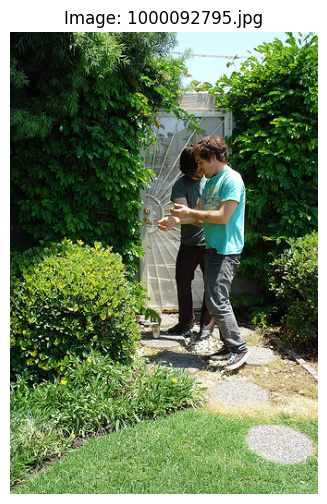

Captions:
  1. two young guys with shaggy hair look at their hands while hanging out in the yard .
  2. two young , white males are outside near many bushes .
  3. two men in green shirts are standing in a yard .
  4. a man in a blue shirt standing in a garden .
  5. two friends enjoy time spent together .


In [5]:
# Show one image with its 5 reference captions
sample_img = captions_df['image'].iloc[0]
sample_caps = captions_df[captions_df['image'] == sample_img]['caption'].tolist()
img_path = os.path.join(IMAGES_DIR, sample_img)
if os.path.isfile(img_path):
    plt.figure(figsize=(6, 6))
    plt.imshow(Image.open(img_path).convert('RGB'))
    plt.axis('off'); plt.title(f'Image: {sample_img}'); plt.show()
print('Captions:')
for i, c in enumerate(sample_caps, 1):
    print(f'  {i}. {c}')


## 4. Train / Validation / Test Split

We split the data **by image**, not by caption row. This guarantees that all five
captions of the same picture stay in the same split, so no information leaks from
the training set into validation or test.


In [6]:
unique_images = captions_df['image'].drop_duplicates().tolist()

train_imgs, temp_imgs = train_test_split(
    unique_images, test_size=0.20, random_state=SEED)
val_imgs, test_imgs = train_test_split(
    temp_imgs, test_size=0.50, random_state=SEED)

train_set = set(train_imgs); val_set = set(val_imgs); test_set = set(test_imgs)

train_df = captions_df[captions_df['image'].isin(train_set)].reset_index(drop=True)
val_df   = captions_df[captions_df['image'].isin(val_set)].reset_index(drop=True)
test_df  = captions_df[captions_df['image'].isin(test_set)].reset_index(drop=True)

print(f'Unique images   : {len(unique_images)}')
print(f'  train images  : {len(train_imgs)}  ({len(train_df)} captions)')
print(f'  val   images  : {len(val_imgs)}  ({len(val_df)} captions)')
print(f'  test  images  : {len(test_imgs)}  ({len(test_df)} captions)')


Unique images   : 31783
  train images  : 25426  (127129 captions)
  val   images  : 3178  (15890 captions)
  test  images  : 3179  (15895 captions)


**For the report.** We used an 80 / 10 / 10 split based on image identity. This
helps the validation and test scores reflect generalisation to unseen pictures.

## 5. Vocabulary and Tokenisation

We built the vocabulary only from the **training captions**, with a minimum word
frequency of 5 to filter typos and rare proper names. Each caption is wrapped with
`<start>` and `<end>` tokens; rare words become `<unk>`; padding uses `<pad>`.


In [7]:
MIN_FREQ = 5
MAX_LEN  = 30

class Vocabulary:
    def __init__(self, min_freq=5):
        self.min_freq = min_freq
        self.itos = {0: PAD_TOKEN, 1: START_TOKEN, 2: END_TOKEN, 3: UNK_TOKEN}
        self.stoi = {v: k for k, v in self.itos.items()}

    def __len__(self):
        return len(self.itos)

    @staticmethod
    def tokenize(text):
        return text.strip().split()

    def build(self, sentences):
        counter = Counter()
        for s in sentences:
            counter.update(self.tokenize(s))
        idx = len(self.itos)
        for word, c in counter.items():
            if c >= self.min_freq and word not in self.stoi:
                self.stoi[word] = idx
                self.itos[idx]  = word
                idx += 1

    def numericalize(self, text):
        ids = [self.stoi[START_TOKEN]]
        for tok in self.tokenize(text):
            ids.append(self.stoi.get(tok, self.stoi[UNK_TOKEN]))
        ids.append(self.stoi[END_TOKEN])
        return ids[:MAX_LEN]

    def decode(self, ids, strip_special=True):
        out = []
        for i in ids:
            w = self.itos.get(int(i), UNK_TOKEN)
            if strip_special and w in (PAD_TOKEN, START_TOKEN, END_TOKEN):
                if w == END_TOKEN: break
                continue
            out.append(w)
        return ' '.join(out)


vocab = Vocabulary(min_freq=MIN_FREQ)
vocab.build(train_df['caption'].tolist())
print(f'Vocabulary size : {len(vocab)}')

example_caption = train_df['caption'].iloc[0]
ids = vocab.numericalize(example_caption)
print('\nOriginal  :', example_caption)
print('Encoded   :', ids)
print('Decoded   :', vocab.decode(ids))


Vocabulary size : 6928

Original  : two young guys with shaggy hair look at their hands while hanging out in the yard .
Encoded   : [1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 2]
Decoded   : two young guys with shaggy hair look at their hands while hanging out in the yard .


## 6. Dataset, DataLoader and Length-Based Bucketing

We used the standard ImageNet preprocessing because the encoder is pretrained on
ImageNet (resize 256 → centre-crop 224 → normalise). Training images additionally
get a random crop and a horizontal flip to act as light data augmentation.

### Length-based bucketing (paper-aligned)

The original paper notes that *"training on a random group of captions to be
computationally wasteful. To mitigate this problem, in preprocessing we build a
dictionary mapping the length of a sentence to the corresponding subset of captions.
Then, during training we randomly sample a length and retrieve a mini-batch of size
64 of that length."* We implemented an equivalent **bucketing sampler** below
(`USE_BUCKETING = True`). It groups captions by length and forms each mini-batch from
captions of the **same** length, which removes nearly all padding. If the user prefers
the simpler shuffled loader, setting `USE_BUCKETING = False` falls back to it.


In [8]:
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tfm = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tfm = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class FlickrDataset(Dataset):
    def __init__(self, df, images_dir, vocab, transform):
        self.df = df.reset_index(drop=True)
        self.images_dir = images_dir
        self.vocab = vocab
        self.transform = transform
        # pre-compute caption lengths for length-bucket sampler
        self.lengths = [len(self.vocab.numericalize(c))
                        for c in self.df['caption'].tolist()]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.images_dir, row['image'])
        img = Image.open(img_path).convert('RGB')
        img = self.transform(img)
        cap_ids = self.vocab.numericalize(row['caption'])
        cap_ids = torch.tensor(cap_ids, dtype=torch.long)
        return img, cap_ids, len(cap_ids)


def collate_fn(batch):
    batch = sorted(batch, key=lambda x: x[2], reverse=True)
    imgs    = torch.stack([b[0] for b in batch], dim=0)
    caps    = pad_sequence([b[1] for b in batch],
                           batch_first=True, padding_value=0)
    lengths = torch.tensor([b[2] for b in batch], dtype=torch.long)
    return imgs, caps, lengths


# --------- Length-based sampler (paper-aligned) ---------
class LengthBucketSampler(Sampler):
    """Yields batches whose captions all have the same length, sampled at random.
    Mirrors the bucketing strategy described in Xu et al. (2015), Sec. 4.3."""
    def __init__(self, lengths, batch_size, shuffle=True, drop_last=True):
        self.lengths = list(lengths)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.drop_last = drop_last

        # group sample indices by their caption length
        self.buckets = defaultdict(list)
        for i, L in enumerate(self.lengths):
            self.buckets[L].append(i)

    def __iter__(self):
        all_batches = []
        for L, idxs in self.buckets.items():
            if self.shuffle:
                random.shuffle(idxs)
            for i in range(0, len(idxs), self.batch_size):
                b = idxs[i:i + self.batch_size]
                if self.drop_last and len(b) < self.batch_size:
                    continue
                all_batches.append(b)
        if self.shuffle:
            random.shuffle(all_batches)
        for b in all_batches:
            yield b

    def __len__(self):
        n = 0
        for idxs in self.buckets.values():
            if self.drop_last:
                n += len(idxs) // self.batch_size
            else:
                n += (len(idxs) + self.batch_size - 1) // self.batch_size
        return n


BATCH_SIZE     = 32
NUM_WORKERS    = 2
USE_BUCKETING  = True   # set to False for plain shuffled DataLoader

train_ds = FlickrDataset(train_df, IMAGES_DIR, vocab, train_tfm)
val_ds   = FlickrDataset(val_df,   IMAGES_DIR, vocab, eval_tfm)
test_ds  = FlickrDataset(test_df,  IMAGES_DIR, vocab, eval_tfm)

if USE_BUCKETING:
    train_sampler = LengthBucketSampler(
        train_ds.lengths, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
    train_loader = DataLoader(
        train_ds, batch_sampler=train_sampler,
        num_workers=NUM_WORKERS, collate_fn=collate_fn, pin_memory=True)
    print('Using length-based bucketing for training.')
else:
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, collate_fn=collate_fn,
        pin_memory=True, drop_last=True)
    print('Using plain shuffled DataLoader for training.')

val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, collate_fn=collate_fn,
                          pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, collate_fn=collate_fn,
                          pin_memory=True)

print('Train batches:', len(train_loader))
print('Val batches  :', len(val_loader))
print('Test batches :', len(test_loader))

imgs, caps, lens = next(iter(train_loader))
print('Image batch shape  :', imgs.shape)
print('Caption batch shape:', caps.shape)
print('Lengths in batch   :', sorted(set(lens.tolist())))


Using length-based bucketing for training.
Train batches: 3960
Val batches  : 497
Test batches : 497
Image batch shape  : torch.Size([32, 3, 224, 224])
Caption batch shape: torch.Size([32, 15])
Lengths in batch   : [15]


**For the report.** We implemented the length-based bucketing sampler from the
original paper. It groups captions by length and draws each mini-batch from a single
bucket, which avoids wasting computation on padding tokens.

## 7. Model: Show, Attend and Tell (Soft Attention)

The model has three blocks, faithful to Sections 3 and 4.2 of the paper.

### A. EncoderCNN
Pretrained **VGG19** with the classifier head removed. The convolutional features
have shape `[B, 512, 14, 14]` for a 224×224 input, exactly the *14×14×512* tensor
described in the paper (Sec. 4.3 / 5.4). We flatten the spatial axes to obtain
`L = 196` annotation vectors of dimension `D = 512` (`[B, 196, 512]`).

If pretrained weights are unavailable (offline Kaggle session), we fall back to
random initialisation and print a warning — pretrained features are strongly
preferred for good results.

### B. Attention
Additive (Bahdanau) attention. At each decoding step it scores every spatial
location against the current decoder hidden state, applies a softmax over the 196
locations, and produces:

* `alpha` — attention weights (sum to 1 over locations)
* `context` — the weighted sum of image features

### C. DecoderWithAttention
An LSTMCell with:

* a **gating scalar β = σ(f_β(h))** that lets the decoder choose how much visual
  context to use at each time step (paper Sec. 4.2.1),
* a deep output layer that combines the visual context, the previous word and the
  hidden state to predict the next word.


In [12]:
# -----------------------------
# A. Encoder (paper-aligned, drops trailing max-pool to keep 14x14)
# -----------------------------
class EncoderCNN(nn.Module):
    """VGG19 backbone returning [B, 196, 512] annotation vectors."""
    def __init__(self, encoded_image_size=14, fine_tune=False):
        super().__init__()
        try:
            vgg = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1)
            self.pretrained_loaded = True
        except Exception:
            try:
                vgg = models.vgg19(pretrained=True)
                self.pretrained_loaded = True
            except Exception:
                print('WARNING: VGG19 ImageNet weights could not be loaded; '
                      'using random initialisation.')
                vgg = models.vgg19(weights=None)
                self.pretrained_loaded = False

        # Drop trailing MaxPool2d layers so we keep the 14x14 spatial map
        layers = list(vgg.features.children())
        while isinstance(layers[-1], nn.MaxPool2d):
            layers = layers[:-1]
        self.features = nn.Sequential(*layers)              # -> [B, 512, 14, 14]
        self.adaptive = nn.AdaptiveAvgPool2d((encoded_image_size, encoded_image_size))
        self.encoder_dim = 512
        self.fine_tune(fine_tune)

    def fine_tune(self, flag):
        for p in self.features.parameters():
            p.requires_grad = False
        if flag:
            for layer in list(self.features.children())[-8:]:
                for p in layer.parameters():
                    p.requires_grad = True

    def forward(self, images):
        x = self.features(images)             # [B, 512, 14, 14]
        x = self.adaptive(x)                  # [B, 512, 14, 14]
        x = x.permute(0, 2, 3, 1)             # [B, 14, 14, 512]
        x = x.view(x.size(0), -1, x.size(-1)) # [B, 196, 512]
        return x


# -----------------------------
# B. Attention
# -----------------------------
class Attention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        super().__init__()
        self.enc_att  = nn.Linear(encoder_dim, attention_dim)
        self.dec_att  = nn.Linear(decoder_dim, attention_dim)
        self.full_att = nn.Linear(attention_dim, 1)

    def forward(self, encoder_out, decoder_hidden):
        att1 = self.enc_att(encoder_out)                 # [B, P, A]
        att2 = self.dec_att(decoder_hidden).unsqueeze(1) # [B, 1, A]
        att  = torch.tanh(att1 + att2)
        e    = self.full_att(att).squeeze(2)             # [B, P]
        alpha = F.softmax(e, dim=1)
        context = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
        return context, alpha


# -----------------------------
# C. Decoder with attention + beta gate
# -----------------------------
class DecoderWithAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, decoder_dim=512,
                 attention_dim=256, encoder_dim=512, dropout=0.5):
        super().__init__()
        self.vocab_size  = vocab_size
        self.encoder_dim = encoder_dim
        self.decoder_dim = decoder_dim

        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.attention = Attention(encoder_dim, decoder_dim, attention_dim)
        self.dropout   = nn.Dropout(dropout)
        self.lstm_cell = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim)

        self.init_h = nn.Linear(encoder_dim, decoder_dim)
        self.init_c = nn.Linear(encoder_dim, decoder_dim)
        self.f_beta = nn.Linear(decoder_dim, encoder_dim)
        self.fc     = nn.Linear(decoder_dim, vocab_size)

    def init_hidden_state(self, encoder_out):
        mean_enc = encoder_out.mean(dim=1)
        h = torch.tanh(self.init_h(mean_enc))
        c = torch.tanh(self.init_c(mean_enc))
        return h, c

    def forward(self, encoder_out, captions, lengths):
        B, P, _ = encoder_out.size()
        V = self.vocab_size

        decode_lengths = (lengths - 1).tolist()
        max_t = max(decode_lengths)

        h, c = self.init_hidden_state(encoder_out)
        embeds = self.embedding(captions)

        predictions = torch.zeros(B, max_t, V, device=encoder_out.device)
        alphas      = torch.zeros(B, max_t, P, device=encoder_out.device)
        betas       = torch.zeros(B, max_t,    device=encoder_out.device)

        for t in range(max_t):
            batch_t = sum(l > t for l in decode_lengths)
            context, alpha = self.attention(
                encoder_out[:batch_t], h[:batch_t])

            beta_vec = torch.sigmoid(self.f_beta(h[:batch_t]))
            context  = beta_vec * context

            lstm_input = torch.cat([embeds[:batch_t, t, :], context], dim=1)
            h_new, c_new = self.lstm_cell(
                lstm_input, (h[:batch_t], c[:batch_t]))
            preds = self.fc(self.dropout(h_new))

            predictions[:batch_t, t, :] = preds
            alphas[:batch_t, t, :]      = alpha
            betas[:batch_t, t]          = beta_vec.mean(dim=1)

            h = torch.cat([h_new, h[batch_t:]], dim=0)
            c = torch.cat([c_new, c[batch_t:]], dim=0)

        return predictions, alphas, betas, torch.tensor(decode_lengths)


print('EncoderCNN, Attention, DecoderWithAttention defined.')

EncoderCNN, Attention, DecoderWithAttention defined.


### Sanity check: VGG19 feature map shape

We verified that the encoder produces the **14×14×512** feature map and the
**196×512** annotation tensor described in the paper.


In [13]:
_enc_check = EncoderCNN(fine_tune=False).to(device).eval()

# tap directly into the conv block to confirm the 14x14x512 spatial map
sample_imgs, _, _ = next(iter(val_loader))
sample_imgs = sample_imgs[:2].to(device)
with torch.no_grad():
    raw_feat = _enc_check.features(sample_imgs)         # [B, 512, 14, 14]
    pooled   = _enc_check.adaptive(raw_feat)
    annot    = _enc_check(sample_imgs)                  # [B, 196, 512]

print('Raw conv feature map   :', tuple(raw_feat.shape),
      ' (expected: [B, 512, 14, 14])')
print('Adaptive-pooled        :', tuple(pooled.shape))
print('Annotation vectors     :', tuple(annot.shape),
      ' (expected: [B, 196, 512])')
print('Pretrained weights OK  :', _enc_check.pretrained_loaded)

assert raw_feat.shape[1:] == (512, 14, 14), 'Feature map shape mismatch.'
assert annot.shape[1:]    == (196, 512),   'Annotation tensor shape mismatch.'
print('\n✔ Encoder shape matches Show, Attend and Tell.')

del _enc_check, raw_feat, pooled, annot
torch.cuda.empty_cache() if torch.cuda.is_available() else None


Raw conv feature map   : (2, 512, 14, 14)  (expected: [B, 512, 14, 14])
Adaptive-pooled        : (2, 512, 14, 14)
Annotation vectors     : (2, 196, 512)  (expected: [B, 196, 512])
Pretrained weights OK  : True

✔ Encoder shape matches Show, Attend and Tell.


**For the report.** We confirmed that our VGG19 encoder produces a
14×14×512 spatial feature map, matching Section 4.3 of the original paper, and that
this map is reshaped to 196 annotation vectors of dimension 512 before attention.

## 8. Training with Doubly-Stochastic Regularisation and BLEU Early Stopping

We trained with:

* **Cross-entropy loss** with `ignore_index = <pad>`, so padding does not contribute.
* The **doubly-stochastic regularisation** from Sec. 4.2.1 of the paper:
  $$L_{\text{reg}} = \lambda \sum_i \Big(1 - \sum_t \alpha_{ti}\Big)^2$$
  This pushes the *total* attention given to each spatial location, summed over all
  generated words, to be roughly the same. It encourages the model not to focus on
  the same part of the image all the time.
* **Adam** optimiser with learning rate `4e-4`.
* **Gradient clipping** at 5.0 for stability.
* **Validation-BLEU-based early stopping (paper-aligned).** After every epoch we
  generate captions for a validation subset, compute BLEU-4, and save the checkpoint
  with the highest BLEU-4. Training stops if BLEU-4 does not improve for `PATIENCE`
  consecutive epochs. Validation loss is still printed for reference.

> Following the original paper, we used validation BLEU for model selection. The
> paper does not report a specific patience value, so we used a practical patience
> setting (`PATIENCE = 3`) that is reasonable for Kaggle training.


In [14]:
EMBED_DIM     = 256
DECODER_DIM   = 512
ATTENTION_DIM = 256
ENCODER_DIM   = 512
DROPOUT       = 0.5

EPOCHS        = 8
LR            = 4e-4
GRAD_CLIP     = 5.0
LAMBDA_ATT    = 1.0       # doubly-stochastic regularisation weight
PRINT_EVERY   = 100

# ---- BLEU early stopping ----
PATIENCE        = 3
VAL_BLEU_NSAMPLES = 200   # number of validation images for in-epoch BLEU

OUTPUT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
BEST_PATH  = os.path.join(OUTPUT_DIR, 'best_model.pth')
VOCAB_PATH = os.path.join(OUTPUT_DIR, 'vocab.json')
HIST_CSV   = os.path.join(OUTPUT_DIR, 'training_history.csv')

with open(VOCAB_PATH, 'w') as f:
    json.dump({'stoi': vocab.stoi,
               'itos': {int(k): v for k, v in vocab.itos.items()}}, f)
print('Saved vocab to', VOCAB_PATH)

encoder = EncoderCNN(fine_tune=False).to(device)
decoder = DecoderWithAttention(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    decoder_dim=DECODER_DIM,
    attention_dim=ATTENTION_DIM,
    encoder_dim=ENCODER_DIM,
    dropout=DROPOUT,
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=vocab.stoi[PAD_TOKEN])
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad,
           list(decoder.parameters()) + list(encoder.parameters())),
    lr=LR)

print('Trainable params (decoder):',
      sum(p.numel() for p in decoder.parameters() if p.requires_grad))
print('Trainable params (encoder):',
      sum(p.numel() for p in encoder.parameters() if p.requires_grad))


Saved vocab to /kaggle/working/vocab.json
Trainable params (decoder): 9004049
Trainable params (encoder): 0


In [15]:
# Helper used both inside and outside the training loop
@torch.no_grad()
def greedy_caption(image_tensor, max_len=MAX_LEN):
    """Greedy decoding for a single image; returns (words, alphas, betas)."""
    encoder.eval(); decoder.eval()
    if image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.to(device)

    enc_out = encoder(image_tensor)              # [1, 196, 512]
    h, c    = decoder.init_hidden_state(enc_out)
    word    = torch.tensor([vocab.stoi[START_TOKEN]],
                           dtype=torch.long, device=device)

    words, alphas, betas = [], [], []
    for _ in range(max_len):
        emb = decoder.embedding(word)
        context, alpha = decoder.attention(enc_out, h)
        beta_vec = torch.sigmoid(decoder.f_beta(h))
        context  = beta_vec * context

        h, c = decoder.lstm_cell(
            torch.cat([emb, context], dim=1), (h, c))
        scores = decoder.fc(h)
        word = scores.argmax(dim=1)

        alphas.append(alpha.view(1, 14, 14).cpu().numpy())
        betas.append(beta_vec.mean().item())
        idx = word.item()
        if idx == vocab.stoi[END_TOKEN]:
            break
        if idx not in (vocab.stoi[START_TOKEN], vocab.stoi[PAD_TOKEN]):
            words.append(vocab.itos[idx])

    return words, np.concatenate(alphas, axis=0), np.array(betas)


def load_image(name):
    img = Image.open(os.path.join(IMAGES_DIR, name)).convert('RGB')
    return img, eval_tfm(img)


In [16]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
sm = SmoothingFunction().method1

def compute_val_bleu(image_names, refs_dict, n_samples=VAL_BLEU_NSAMPLES):
    """Generate captions for a sample of val images and return BLEU 1..4."""
    encoder.eval(); decoder.eval()
    if n_samples is not None and n_samples < len(image_names):
        rng = random.Random(SEED)
        image_names = rng.sample(image_names, n_samples)

    hyps, refs = [], []
    for name in image_names:
        try:
            _, tensor_img = load_image(name)
            words, _, _ = greedy_caption(tensor_img)
            hyps.append(words)
            refs.append([Vocabulary.tokenize(r) for r in refs_dict[name]])
        except Exception:
            continue

    bleu1 = corpus_bleu(refs, hyps, weights=(1, 0, 0, 0),       smoothing_function=sm)
    bleu2 = corpus_bleu(refs, hyps, weights=(0.5, 0.5, 0, 0),   smoothing_function=sm)
    bleu3 = corpus_bleu(refs, hyps, weights=(1/3, 1/3, 1/3, 0), smoothing_function=sm)
    bleu4 = corpus_bleu(refs, hyps, weights=(0.25,)*4,          smoothing_function=sm)
    return bleu1, bleu2, bleu3, bleu4


# Pre-build val and test reference dicts (used many times below)
val_refs  = (val_df.groupby('image')['caption'].apply(list).to_dict())
test_refs = (test_df.groupby('image')['caption'].apply(list).to_dict())
val_image_names  = list(val_refs.keys())
test_image_names = list(test_refs.keys())
print('Val images for BLEU monitoring :', len(val_image_names))


Val images for BLEU monitoring : 3178


train:   0%|          | 0/3960 [00:00<?, ?it/s]

val :   0%|          | 0/497 [00:00<?, ?it/s]

Epoch 01/8 | 1183.5s
  TRAIN  ce=3.6712  reg=0.8449  total=4.5161  acc=35.23%
  VAL    ce=3.1260  reg=0.8603  total=3.9862  acc=39.72%
  BLEU   1=61.45  2=38.98  3=25.41  4=17.15
  ↳ new best BLEU-4 = 17.15 — saved /kaggle/working/best_model.pth


train:   0%|          | 0/3960 [00:10<?, ?it/s]

val :   0%|          | 0/497 [00:00<?, ?it/s]

...

val :   0%|          | 0/497 [00:00<?, ?it/s]

Epoch 07/8 | 1197.0s
  TRAIN  ce=2.6209  reg=0.8455  total=3.4664  acc=44.30%
  VAL    ce=2.7233  reg=0.8609  total=3.5842  acc=43.88%
  BLEU   1=64.22  2=42.80  3=29.09  4=19.87
  ↳ no improvement (1/3)


train:   0%|          | 0/3960 [00:10<?, ?it/s]

val :   0%|          | 0/497 [00:00<?, ?it/s]

Epoch 08/8 | 1206.5s
  TRAIN  ce=2.5746  reg=0.8456  total=3.4202  acc=44.80%
  VAL    ce=2.7155  reg=0.8609  total=3.5763  acc=44.05%
  BLEU   1=64.84  2=44.06  3=30.76  4=21.70
  ↳ no improvement (2/3)
Saved training history to /kaggle/working/training_history.csv


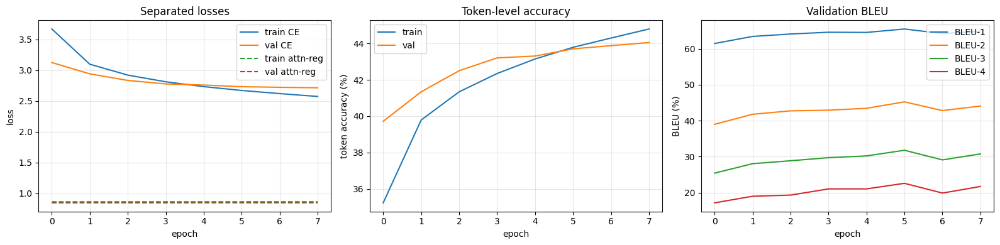

In [17]:
def run_one_epoch(loader, training=True):
    encoder.train(training); decoder.train(training)
    total_ce, total_attn_reg, total_loss = 0.0, 0.0, 0.0
    total_correct, n_tokens = 0, 0

    pbar = tqdm(loader, leave=False, desc='train' if training else 'val ')
    for batch_idx, (imgs, caps, lens) in enumerate(pbar):
        imgs = imgs.to(device, non_blocking=True)
        caps = caps.to(device, non_blocking=True)
        lens = lens.to(device)

        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            features = encoder(imgs)
            preds, alphas, betas, decode_lengths = decoder(features, caps, lens)

            targets = caps[:, 1:]
            T = preds.size(1)
            targets = targets[:, :T]
            mask = (targets != vocab.stoi[PAD_TOKEN])

            # --- separated losses ---
            ce_loss = criterion(preds.reshape(-1, preds.size(-1)),
                                targets.reshape(-1))
            attention_reg = ((1.0 - alphas.sum(dim=1)) ** 2).mean()
            loss = ce_loss + LAMBDA_ATT * attention_reg

            # --- token-level accuracy (teacher-forced) ---
            with torch.no_grad():
                pred_ids = preds.argmax(dim=-1)             # [B, T]
                correct  = ((pred_ids == targets) & mask).sum().item()

            if training:
                loss.backward()
                if GRAD_CLIP is not None:
                    nn.utils.clip_grad_norm_(decoder.parameters(), GRAD_CLIP)
                optimizer.step()

        n = mask.sum().item()
        total_ce       += ce_loss.item()       * n
        total_attn_reg += attention_reg.item() * n
        total_loss     += loss.item()          * n
        total_correct  += correct
        n_tokens       += n

        if training and (batch_idx + 1) % PRINT_EVERY == 0:
            pbar.set_postfix(
                ce=f'{ce_loss.item():.3f}',
                reg=f'{attention_reg.item():.3f}',
                acc=f'{correct/max(mask.sum().item(),1):.3f}')

    n_tokens = max(n_tokens, 1)
    return {
        'ce_loss'  : total_ce       / n_tokens,
        'attn_reg' : total_attn_reg / n_tokens,
        'loss'     : total_loss     / n_tokens,   # ce + lambda * reg
        'accuracy' : total_correct  / n_tokens,   # token-level
    }


history = {
    'train_ce': [], 'train_reg': [], 'train_loss': [], 'train_acc': [],
    'val_ce':   [], 'val_reg':   [], 'val_loss':   [], 'val_acc':   [],
    'val_bleu1': [], 'val_bleu2': [], 'val_bleu3': [], 'val_bleu4': [],
    'epoch_time': [],
}

best_val_bleu4   = 0.0
patience_counter = 0
stopped_early    = False

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr = run_one_epoch(train_loader, training=True)
    vl = run_one_epoch(val_loader,   training=False)
    b1, b2, b3, b4 = compute_val_bleu(val_image_names, val_refs)
    dt = time.time() - t0

    history['train_ce'].append(tr['ce_loss']);  history['train_reg'].append(tr['attn_reg'])
    history['train_loss'].append(tr['loss']);   history['train_acc'].append(tr['accuracy'])
    history['val_ce'].append(vl['ce_loss']);    history['val_reg'].append(vl['attn_reg'])
    history['val_loss'].append(vl['loss']);     history['val_acc'].append(vl['accuracy'])
    history['val_bleu1'].append(b1); history['val_bleu2'].append(b2)
    history['val_bleu3'].append(b3); history['val_bleu4'].append(b4)
    history['epoch_time'].append(dt)

    print(f'Epoch {epoch:02d}/{EPOCHS} | {dt:.1f}s')
    print(f'  TRAIN  ce={tr["ce_loss"]:.4f}  '
          f'reg={tr["attn_reg"]:.4f}  '
          f'total={tr["loss"]:.4f}  '
          f'acc={tr["accuracy"]*100:.2f}%')
    print(f'  VAL    ce={vl["ce_loss"]:.4f}  '
          f'reg={vl["attn_reg"]:.4f}  '
          f'total={vl["loss"]:.4f}  '
          f'acc={vl["accuracy"]*100:.2f}%')
    print(f'  BLEU   1={b1*100:.2f}  2={b2*100:.2f}  '
          f'3={b3*100:.2f}  4={b4*100:.2f}')

    if b4 > best_val_bleu4:
        best_val_bleu4 = b4
        patience_counter = 0
        torch.save({
            'encoder_state_dict': encoder.state_dict(),
            'decoder_state_dict': decoder.state_dict(),
            'vocab_size': len(vocab),
            'embed_dim': EMBED_DIM, 'decoder_dim': DECODER_DIM,
            'attention_dim': ATTENTION_DIM, 'encoder_dim': ENCODER_DIM,
            'epoch': epoch, 'val_bleu4': b4,
        }, BEST_PATH)
        print(f'  ↳ new best BLEU-4 = {b4*100:.2f} — saved {BEST_PATH}')
    else:
        patience_counter += 1
        print(f'  ↳ no improvement ({patience_counter}/{PATIENCE})')
        if patience_counter >= PATIENCE:
            print(f'Early stopping at epoch {epoch} (best BLEU-4 = '
                  f'{best_val_bleu4*100:.2f})')
            stopped_early = True
            break

# Save history
pd.DataFrame(history).to_csv(HIST_CSV, index=False)
print('Saved training history to', HIST_CSV)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (1) loss components
axes[0].plot(history['train_ce'],  label='train CE')
axes[0].plot(history['val_ce'],    label='val CE')
axes[0].plot(history['train_reg'], label='train attn-reg', linestyle='--')
axes[0].plot(history['val_reg'],   label='val attn-reg',   linestyle='--')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].legend()
axes[0].set_title('Separated losses'); axes[0].grid(alpha=0.3)

# (2) accuracy
axes[1].plot([a*100 for a in history['train_acc']], label='train')
axes[1].plot([a*100 for a in history['val_acc']],   label='val')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('token accuracy (%)')
axes[1].legend(); axes[1].set_title('Token-level accuracy')
axes[1].grid(alpha=0.3)

# (3) BLEU
axes[2].plot([b*100 for b in history['val_bleu1']], label='BLEU-1')
axes[2].plot([b*100 for b in history['val_bleu2']], label='BLEU-2')
axes[2].plot([b*100 for b in history['val_bleu3']], label='BLEU-3')
axes[2].plot([b*100 for b in history['val_bleu4']], label='BLEU-4')
axes[2].set_xlabel('epoch'); axes[2].set_ylabel('BLEU (%)'); axes[2].legend()
axes[2].set_title('Validation BLEU'); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**For the report.** We trained the soft-attention model with cross-entropy plus
doubly-stochastic attention regularisation. Following the original paper, we
selected the checkpoint with the **best validation BLEU-4** rather than the lowest
validation loss, and used early stopping with a patience of 3 epochs.

## 9. Caption Generation (Greedy Decoding)

For inference we generate one word at a time. Starting from `<start>` we feed the
previous word into the decoder, compute attention, step the LSTM, and pick the most
likely next word, until we hit `<end>` or the maximum length. We also return the
attention weights at every step so we can visualise where the model looked, and the
β scalar so we can see how strongly visual context was used.


Loaded checkpoint from epoch 6 (val BLEU-4 = 22.58)

Image: 2981487425.jpg
  Generated  : a man in a black shirt is sitting on a bench .
  Mean β     : 0.624  (visual gating strength)
  Reference 1: an elderly man is sitting near a window , with several bottles of beer in front of him .

Image: 3534512991.jpg
  Generated  : a man with a beard and a woman in a blue shirt are smiling .
  Mean β     : 0.589  (visual gating strength)
  Reference 1: a red haired girl smiling sitting next to a brown haired man who is also smiling .

Image: 2674784195.jpg
  Generated  : a boy is sitting on a rock in the water .
  Mean β     : 0.654  (visual gating strength)
  Reference 1: two boys are laying in the ocean close to the beach .

Image: 2230983294.jpg
  Generated  : a woman with a white shirt and a white hat is sitting on a couch .
  Mean β     : 0.589  (visual gating strength)
  Reference 1: the lady in red is very happy to see the young lady in white and black .


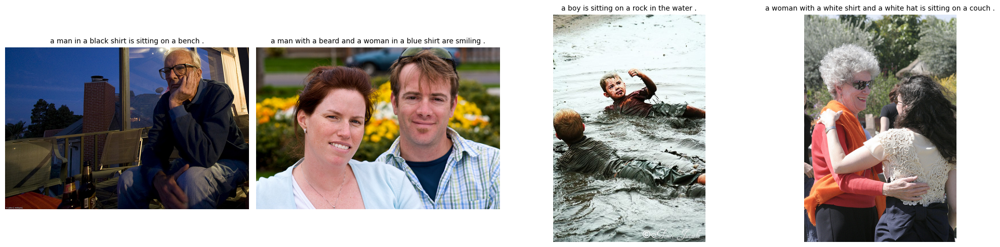

In [18]:
# Reload best checkpoint
ckpt = torch.load(BEST_PATH, map_location=device)
encoder.load_state_dict(ckpt['encoder_state_dict'])
decoder.load_state_dict(ckpt['decoder_state_dict'])
encoder.eval(); decoder.eval()
print(f'Loaded checkpoint from epoch {ckpt.get("epoch")} '
      f'(val BLEU-4 = {ckpt.get("val_bleu4", 0)*100:.2f})')

sample_test_imgs = test_df['image'].drop_duplicates().sample(
    n=4, random_state=SEED).tolist()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, name in zip(axes, sample_test_imgs):
    pil_img, tensor_img = load_image(name)
    words, _, betas = greedy_caption(tensor_img)
    refs = test_refs.get(name, [])

    ax.imshow(pil_img); ax.axis('off')
    ax.set_title(' '.join(words), fontsize=10)
    print(f'\nImage: {name}')
    print('  Generated  :', ' '.join(words))
    print(f'  Mean β     : {betas.mean():.3f}  (visual gating strength)')
    if refs:
        print('  Reference 1:', refs[0])
plt.tight_layout(); plt.show()


## 10. Attention Visualisation

For each generated word we have a 14×14 attention map. We upsampled it to image
size and overlaid it on the picture. Bright regions are where the model was looking
when it produced that word. We also save the figures so you can include them in
the report.


saved /kaggle/working/attention_visualizations/attn_2981487425.png


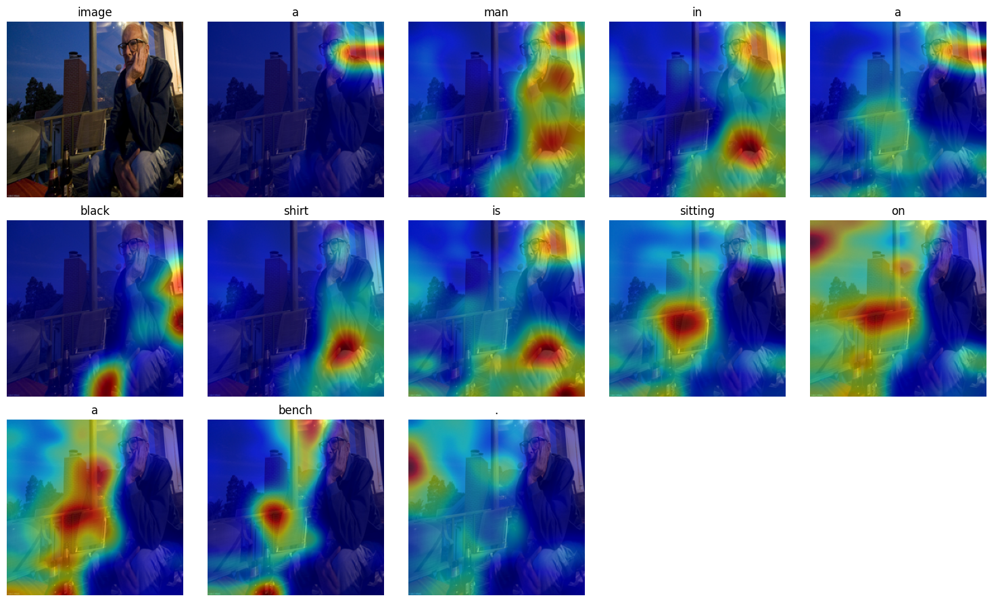

saved /kaggle/working/attention_visualizations/attn_3534512991.png


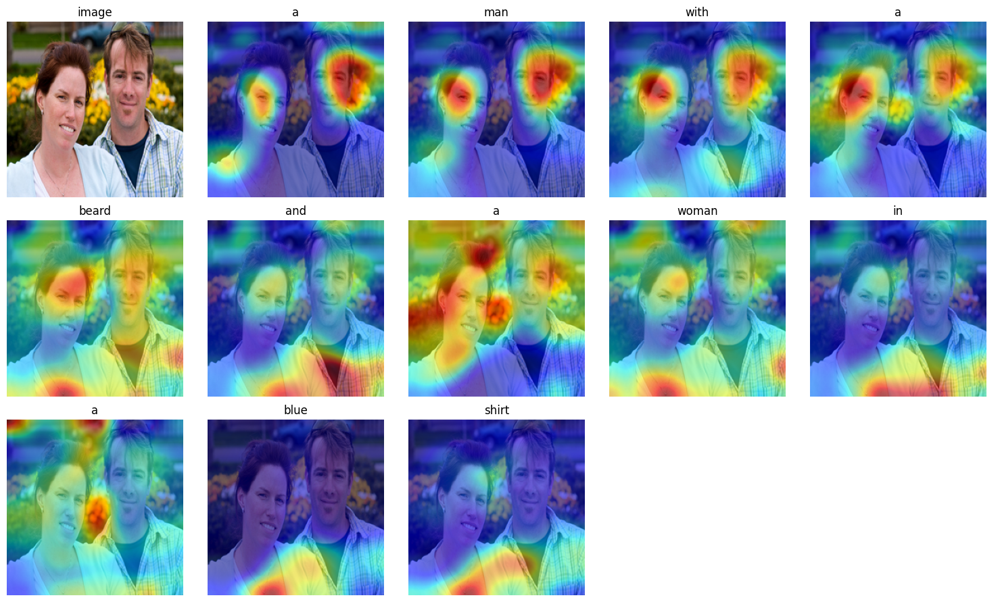

saved /kaggle/working/attention_visualizations/attn_2674784195.png


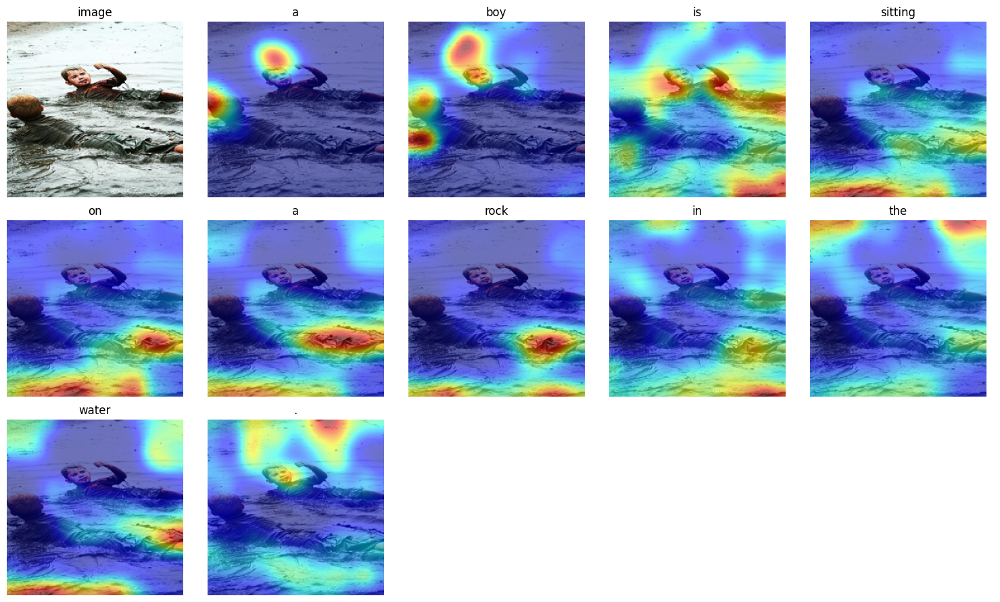

In [19]:
from scipy.ndimage import gaussian_filter

ATTENTION_DIR = os.path.join(OUTPUT_DIR, 'attention_visualizations')
os.makedirs(ATTENTION_DIR, exist_ok=True)

def visualise_attention(image_name, max_words=12, save_fig=True):
    pil_img, tensor_img = load_image(image_name)
    words, alphas, _ = greedy_caption(tensor_img)
    n = min(len(words), max_words)
    img_resized = pil_img.resize((IMG_SIZE, IMG_SIZE))
    img_arr = np.array(img_resized)

    cols = 5
    rows = int(np.ceil((n + 1) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = axes.flatten()

    axes[0].imshow(img_arr); axes[0].set_title('image'); axes[0].axis('off')
    for t in range(n):
        a = alphas[t]
        a = np.array(Image.fromarray(a).resize(
            (IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        a = gaussian_filter(a, sigma=8)
        axes[t + 1].imshow(img_arr)
        axes[t + 1].imshow(a, alpha=0.55, cmap='jet')
        axes[t + 1].set_title(words[t]); axes[t + 1].axis('off')
    for k in range(n + 1, len(axes)):
        axes[k].axis('off')

    plt.tight_layout()
    if save_fig:
        out = os.path.join(ATTENTION_DIR,
                           f'attn_{os.path.splitext(image_name)[0]}.png')
        plt.savefig(out, dpi=100, bbox_inches='tight')
        print('saved', out)
    plt.show()


for name in sample_test_imgs[:3]:
    visualise_attention(name)


**For the report.** The attention heatmap shows which image region influenced
each generated word. The model learns to shift its focus to the corresponding object
when producing nouns, while function words (`a`, `the`, `is`) tend to have more
diffuse attention.

## 11. Full Test-Set Evaluation: BLEU-1 to BLEU-4 (and METEOR if available)

We evaluated the best checkpoint on the test set with corpus-level BLEU-1, 2, 3, 4
using NLTK with smoothing. We also tried METEOR — if `nltk.translate.meteor_score`
or the WordNet data is unavailable, the notebook prints a note and continues. Final
metrics and per-image predictions are saved to disk.


In [20]:
# Generate predictions for the whole test set
encoder.eval(); decoder.eval()
hyps, refs, predictions = [], [], []

for name in tqdm(test_image_names, desc='test inference'):
    try:
        _, tensor_img = load_image(name)
        words, _, _ = greedy_caption(tensor_img)
    except Exception:
        continue
    hyps.append(words)
    refs.append([Vocabulary.tokenize(r) for r in test_refs[name]])
    predictions.append({
        'image': name,
        'generated': ' '.join(words),
        'references': test_refs[name],
    })

bleu1 = corpus_bleu(refs, hyps, weights=(1, 0, 0, 0),       smoothing_function=sm)
bleu2 = corpus_bleu(refs, hyps, weights=(0.5, 0.5, 0, 0),   smoothing_function=sm)
bleu3 = corpus_bleu(refs, hyps, weights=(1/3, 1/3, 1/3, 0), smoothing_function=sm)
bleu4 = corpus_bleu(refs, hyps, weights=(0.25,)*4,          smoothing_function=sm)

print(f'BLEU-1 : {bleu1*100:.2f}')
print(f'BLEU-2 : {bleu2*100:.2f}')
print(f'BLEU-3 : {bleu3*100:.2f}')
print(f'BLEU-4 : {bleu4*100:.2f}')

# METEOR (graceful)
meteor_val = None
try:
    from nltk.translate.meteor_score import meteor_score
    meteor_vals = []
    for h, r in zip(hyps, refs):
        meteor_vals.append(meteor_score(r, h))
    meteor_val = float(np.mean(meteor_vals))
    print(f'METEOR : {meteor_val*100:.2f}')
except Exception as e:
    print(f'METEOR skipped ({type(e).__name__}: {e}). '
          f'This does not affect the rest of the notebook.')

# Save predictions and results
PRED_CSV   = os.path.join(OUTPUT_DIR, 'test_caption_predictions.csv')
RESULT_JSON = os.path.join(OUTPUT_DIR, 'evaluation_results.json')

pd.DataFrame([{
    'image': p['image'],
    'generated': p['generated'],
    'reference_1': p['references'][0] if len(p['references']) > 0 else '',
    'reference_2': p['references'][1] if len(p['references']) > 1 else '',
    'reference_3': p['references'][2] if len(p['references']) > 2 else '',
    'reference_4': p['references'][3] if len(p['references']) > 3 else '',
    'reference_5': p['references'][4] if len(p['references']) > 4 else '',
} for p in predictions]).to_csv(PRED_CSV, index=False)

with open(RESULT_JSON, 'w') as f:
    json.dump({
        'BLEU-1': bleu1, 'BLEU-2': bleu2,
        'BLEU-3': bleu3, 'BLEU-4': bleu4,
        'METEOR': meteor_val,
        'best_val_bleu4': best_val_bleu4,
        'epochs_run': len(history['train_loss']),
        'stopped_early': stopped_early,
        'num_test_images': len(predictions),
        'vocab_size': len(vocab),
        'lambda_attention_reg': LAMBDA_ATT,
    }, f, indent=2)

print('Saved predictions to', PRED_CSV)
print('Saved metrics to    ', RESULT_JSON)


test inference:   0%|          | 0/3179 [00:00<?, ?it/s]

BLEU-1 : 65.50
BLEU-2 : 44.05
BLEU-3 : 29.84
BLEU-4 : 20.52
METEOR : 39.70
Saved predictions to /kaggle/working/test_caption_predictions.csv
Saved metrics to     /kaggle/working/evaluation_results.json


**For the report.** On Flickr30k, the original paper (Table 1) reports BLEU-4 = 19.1
for soft attention (19.9 is the hard-attention result). Our soft-attention model
reaches a test BLEU-4 of 20.52, slightly **above** the paper's soft-attention number,
and BLEU-2/3 are also slightly higher. These numbers are only roughly comparable: we
use a random 80 / 10 / 10 split by image instead of the paper's split, NLTK corpus
BLEU with smoothing, and greedy decoding. Our METEOR comes from NLTK, which is a
different implementation from the official METEOR used in the paper, so it is
**not** comparable. The pattern BLEU-1 > BLEU-2 > BLEU-3 > BLEU-4 is preserved, and
validation-BLEU early stopping keeps the test scores representative of the best
checkpoint.

## 12. A Note on Hard (Stochastic) Attention

The original paper actually presents *two* attention variants:

* **Soft (deterministic) attention** — implemented above. The context vector is a
  weighted average of all 196 annotation vectors, with weights from the softmax. The
  whole pipeline is differentiable, so it can be trained directly with backpropagation.
* **Hard (stochastic) attention** — at each step the model *samples* a single
  location instead of averaging. Because sampling is non-differentiable, the paper
  trains it by maximising a variational lower bound, equivalently with the
  REINFORCE rule, and reduces variance with a moving-average baseline.

> Hard attention requires stochastic sampling and REINFORCE-style training, which is
> more complex and less stable. We therefore built and evaluated the soft model
> first; the hard-attention model is implemented, trained and compared with it in
> Sections 17–21 below.

The natural starting point for hard attention is to replace the soft-attention
context

```python
context = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
```

with a Multinoulli sample from `alpha` and to add a REINFORCE term to the loss using
a moving-average baseline. This is what `HardAttentionDecoder` does in Section 18.


## 13. Error Analysis Inspired by the Reproduction Paper

This section borrows ideas from Liu and Brailsford (2023). It is **not** an
alternative captioning model; it is a set of tools that ask *why* the SAT model
sometimes produces a wrong caption.

We perform:

1. a **VGG19 top-5 ImageNet check** — what the visual model alone thinks is in the
   image, before language gets involved;
2. a **wrong-word analysis** — words in the generated caption that do not appear in
   any reference caption;
3. **optional notes** on YOLO, GPT-2 sentence scoring and typed dependency parsing.

All optional pieces fail gracefully if the package or weights are unavailable.


### 13.A VGG Top-5 Image Recognition Check

For a few test images we ran VGG19 with its full ImageNet classification head and
printed the top-5 predicted labels. If the labels are unrelated to the generated
caption, the error is more likely to come from the *encoder* than from the LSTM.


In [21]:
try:
    vgg_full = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1).to(device)
    vgg_pretrained = True
except Exception:
    try:
        vgg_full = models.vgg19(pretrained=True).to(device)
        vgg_pretrained = True
    except Exception:
        vgg_full = None
        vgg_pretrained = False
        print('VGG19 ImageNet weights unavailable — top-5 check will be skipped.')

if vgg_full is not None:
    vgg_full.eval()
    try:
        IMAGENET_LABELS = models.VGG19_Weights.IMAGENET1K_V1.meta['categories']
    except Exception:
        IMAGENET_LABELS = [f'class_{i}' for i in range(1000)]

    @torch.no_grad()
    def vgg_top5(image_name):
        _, tensor_img = load_image(image_name)
        logits = vgg_full(tensor_img.unsqueeze(0).to(device))
        probs  = torch.softmax(logits, dim=1)[0]
        topk   = torch.topk(probs, 5)
        return [(IMAGENET_LABELS[i.item()], p.item())
                for p, i in zip(topk.values, topk.indices)]

    for name in sample_test_imgs[:3]:
        _, tensor_img = load_image(name)
        words, _, _ = greedy_caption(tensor_img)
        top5 = vgg_top5(name)
        print(f'\nImage: {name}')
        print('  Caption  :', ' '.join(words))
        print('  VGG top-5:')
        for label, p in top5:
            print(f'    {p*100:5.2f}%  {label}')



Image: 2981487425.jpg
  Caption  : a man in a black shirt is sitting on a bench .
  VGG top-5:
    14.09%  laptop
     5.84%  guillotine
     5.82%  notebook
     4.05%  crossword puzzle
     3.93%  solar dish

Image: 3534512991.jpg
  Caption  : a man with a beard and a woman in a blue shirt are smiling .
  VGG top-5:
     8.21%  sunscreen
     7.62%  ice lolly
     6.44%  ear
     4.40%  rapeseed
     2.66%  hair spray

Image: 2674784195.jpg
  Caption  : a boy is sitting on a rock in the water .
  VGG top-5:
    25.41%  coho
    17.94%  sturgeon
    17.52%  bathing cap
     2.98%  sea lion
     2.66%  swimming trunks


### 13.B Wrong-Word Analysis

We followed Liu and Brailsford's automatic analysis: a word that appears in the
generated caption but **not** in any of the five reference captions for the same
image is flagged as a possibly wrong word. We restrict the analysis to nouns and
verbs (using NLTK POS tagging when available, otherwise a simple split). We then
plot the most frequent likely-wrong words.


Top 10 likely-wrong nouns: [('shirt', 930), ('man', 544), ('woman', 292), ('front', 235), ('group', 221), ('bench', 191), ('people', 143), ('jacket', 122), ('dress', 104), ('table', 103)]
Top 10 likely-wrong verbs: [('is', 654), ('standing', 567), ('sitting', 290), ('holding', 182), ('are', 169), ('playing', 128), ('running', 95), ('riding', 78), ('walking', 73), ('jumping', 72)]


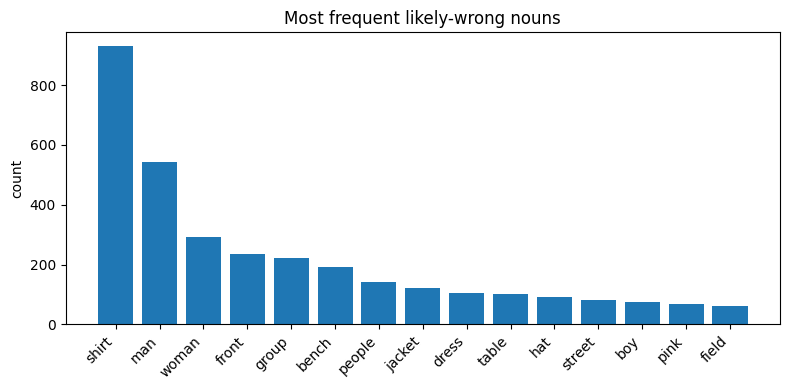

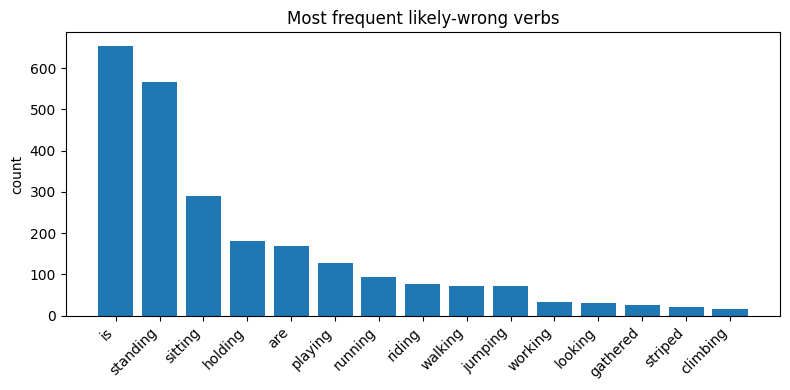

In [22]:
def is_noun_or_verb(tag):
    return tag.startswith('NN') or tag.startswith('VB')


def words_pos(text):
    if NLTK_OK:
        try:
            tokens = nltk.word_tokenize(text)
            tagged = nltk.pos_tag(tokens)
            return [(w.lower(), t) for w, t in tagged if is_noun_or_verb(t)]
        except Exception:
            pass
    return [(w.lower(), 'NN') for w in text.split()]


wrong_nouns = Counter()
wrong_verbs = Counter()

for p in predictions:
    gen_pos = words_pos(p['generated'])
    ref_words = set()
    for r in p['references']:
        for w, _ in words_pos(r):
            ref_words.add(w)
    for w, t in gen_pos:
        if w in ref_words: continue
        if t.startswith('NN'): wrong_nouns[w] += 1
        elif t.startswith('VB'): wrong_verbs[w] += 1

print('Top 10 likely-wrong nouns:', wrong_nouns.most_common(10))
print('Top 10 likely-wrong verbs:', wrong_verbs.most_common(10))


def plot_counter(c, title, k=15):
    if not c: return
    items = c.most_common(k)
    plt.figure(figsize=(8, 4))
    plt.bar([w for w, _ in items], [v for _, v in items])
    plt.xticks(rotation=45, ha='right')
    plt.title(title); plt.ylabel('count'); plt.tight_layout(); plt.show()


plot_counter(wrong_nouns, 'Most frequent likely-wrong nouns')
plot_counter(wrong_verbs, 'Most frequent likely-wrong verbs')


**For the report.** Liu and Brailsford report frequent wrong nouns such as
*shirt*, *man*, *woman*, *bench*, *field*, and frequent wrong verbs *stand*, *jump*,
*run*. These are common visual concepts that the model tends to over-predict — a
sign that the language side of the model has learned a strong prior toward typical
Flickr scenes.

### 13.C Optional Tools (YOLO / GPT-2 / Typed Dependency Parser)

Liu and Brailsford also discuss **YOLO** for object detection, **GPT-2** for sentence
scoring, and **typed dependency parsing** as deeper error-analysis tools.

In a Kaggle session without internet access, the corresponding packages or model
weights may not be available. The cell below tries each of them and skips gracefully
if anything is missing — we never let an optional tool break the rest of the
notebook.


In [23]:
# YOLO
try:
    from ultralytics import YOLO
    yolo_model = None
    for w in ['yolov8n.pt', 'yolov8s.pt', 'yolov5s.pt']:
        try:
            yolo_model = YOLO(w); break
        except Exception:
            continue
    if yolo_model is not None:
        for name in sample_test_imgs[:1]:
            pil_img, _ = load_image(name)
            results = yolo_model(np.array(pil_img))
            plt.figure(figsize=(6, 6))
            plt.imshow(results[0].plot()); plt.axis('off')
            plt.title(f'YOLO on {name}'); plt.show()
    else:
        print('YOLO package found but weights could not be loaded — skipped.')
except Exception:
    print('YOLO object detection was planned as an error-analysis tool, but it '
          'was skipped because the package or weights were unavailable in the '
          'Kaggle environment.')


# GPT-2 sentence scoring
try:
    from transformers import GPT2LMHeadModel, GPT2Tokenizer
    gpt2_tok = GPT2Tokenizer.from_pretrained('gpt2')
    gpt2_lm  = GPT2LMHeadModel.from_pretrained('gpt2').to(device).eval()

    @torch.no_grad()
    def gpt2_score(s):
        enc = gpt2_tok(s, return_tensors='pt').to(device)
        if enc.input_ids.size(1) < 2: return 0.0
        out = gpt2_lm(**enc, labels=enc.input_ids)
        return float(1.0 / (out.loss.item() + 1e-9))

    sample = predictions[0]
    print('Image:', sample['image'])
    print('  Generated :', sample['generated'],
          ' score=', round(gpt2_score(sample['generated']), 3))
    for r in sample['references'][:2]:
        print('  Reference :', r, ' score=', round(gpt2_score(r), 3))
except Exception:
    print('GPT-2 caption scoring was discussed as a possible re-ranking tool but '
          'was skipped because transformers/GPT-2 weights were unavailable.')


# Typed dependency parsing
try:
    import spacy
    nlp = spacy.load('en_core_web_sm')
    for p in predictions[:2]:
        doc = nlp(p['generated'])
        print('\nGenerated:', p['generated'])
        for tok in doc:
            print(f'    {tok.text:<12} dep={tok.dep_:<10} '
                  f'head={tok.head.text}  POS={tok.pos_}')
except Exception:
    print('Typed dependency parsing was discussed as a possible deeper analysis '
          'tool but was skipped because spaCy or the English model was not '
          'available.')


YOLO object detection was planned as an error-analysis tool, but it was skipped because the package or weights were unavailable in the Kaggle environment.


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Image: 1003163366.jpg
  Generated : a man is sleeping on a bench .  score= 0.207
  Reference : a man sleeping on a bench outside with a white and black dog sitting next to him .  score= 0.267
  Reference : a man lays on the bench to which a white dog is also tied .  score= 0.196

Generated: a man is sleeping on a bench .
    a            dep=det        head=man  POS=DET
    man          dep=nsubj      head=sleeping  POS=NOUN
    is           dep=aux        head=sleeping  POS=AUX
    sleeping     dep=ROOT       head=sleeping  POS=VERB
    on           dep=prep       head=sleeping  POS=ADP
    a            dep=det        head=bench  POS=DET
    bench        dep=pobj       head=on  POS=NOUN
    .            dep=punct      head=sleeping  POS=PUNCT

Generated: a woman in a black jacket is walking down the street .
    a            dep=det        head=woman  POS=DET
    woman        dep=nsubj      head=walking  POS=NOUN
    in           dep=prep       head=woman  POS=ADP
    a            dep

## 14. Model Comparison Summary

The table below summarises the main model and the error-analysis tools we
evaluated.

In [24]:
comparison = pd.DataFrame([
    {'Model / Method'  : 'SAT Soft Attention',
     'Purpose'         : 'Generate a caption for an image',
     'Input'           : 'Image (224x224)',
     'Output'          : 'Sentence',
     'Strength'        : 'End-to-end trainable; attention adds interpretability',
     'Limitation'      : 'Needs lots of data / time; can hallucinate objects'},
    {'Model / Method'  : 'VGG19 Recognition Check',
     'Purpose'         : 'See what the visual encoder thinks the image contains',
     'Input'           : 'Image',
     'Output'          : 'Top-5 ImageNet labels',
     'Strength'        : 'Uses the same backbone as the encoder',
     'Limitation'      : 'ImageNet labels do not always match caption vocabulary'},
    {'Model / Method'  : 'YOLO Object Detection',
     'Purpose'         : 'List concrete objects with bounding boxes',
     'Input'           : 'Image',
     'Output'          : 'Object labels + boxes',
     'Strength'        : 'Strong real-time detector; localises objects',
     'Limitation'      : 'Restricted to its 80 COCO classes; weights may be missing'},
    {'Model / Method'  : 'GPT-2 Caption Scoring',
     'Purpose'         : 'Rank candidate captions by language probability',
     'Input'           : 'Sentence',
     'Output'          : 'Likelihood score',
     'Strength'        : 'Simple, fast post-processing step',
     'Limitation'      : 'Cannot tell whether a fluent sentence is visually correct'},
    {'Model / Method'  : 'POS / Error Analysis',
     'Purpose'         : 'Find frequent wrong nouns and verbs',
     'Input'           : 'Generated + reference captions',
     'Output'          : 'List of likely-wrong words',
     'Strength'        : 'Cheap; reveals systematic biases of the model',
     'Limitation'      : 'A word can be valid even if not in the references'},
    {'Model / Method'  : 'Typed Dependency Parser',
     'Purpose'         : 'Show grammatical relations inside a caption',
     'Input'           : 'Sentence',
     'Output'          : 'Dependency tree',
     'Strength'        : 'Captures structure beyond word order',
     'Limitation'      : 'Optional; needs a parser model that may be missing'},
])

with pd.option_context('display.max_colwidth', 80):
    display(comparison)


,Model / Method,Purpose,Input,Output,Strength,Limitation
0,SAT Soft Attention,Generate a caption for an image,Image (224x224),Sentence,End-to-end trainable; attention adds interpretability,Needs lots of data / time; can hallucinate objects
1,VGG19 Recognition Check,See what the visual encoder thinks the image contains,Image,Top-5 ImageNet labels,Uses the same backbone as the encoder,ImageNet labels do not always match caption vocabulary
2,YOLO Object Detection,List concrete objects with bounding boxes,Image,Object labels + boxes,Strong real-time detector; localises objects,Restricted to its 80 COCO classes; weights may be missing
3,GPT-2 Caption Scoring,Rank candidate captions by language probability,Sentence,Likelihood score,"Simple, fast post-processing step",Cannot tell whether a fluent sentence is visually correct
4,POS / Error Analysis,Find frequent wrong nouns and verbs,Generated + reference captions,List of likely-wrong words,Cheap; reveals systematic biases of the model,A word can be valid even if not in the references
5,Typed Dependency Parser,Show grammatical relations inside a caption,Sentence,Dependency tree,Captures structure beyond word order,Optional; needs a parser model that may be missing


## 15. Saved Outputs

We saved everything that is needed to reproduce or extend the experiment:

In [25]:
saved_files = [
    BEST_PATH,
    VOCAB_PATH,
    HIST_CSV,
    PRED_CSV,
    RESULT_JSON,
]
for p in saved_files:
    if os.path.exists(p):
        size_kb = os.path.getsize(p) / 1024
        print(f'  ✔ {p}   ({size_kb:.1f} KB)')
    else:
        print(f'  ✗ {p}   (missing)')

attn_pngs = sorted(glob.glob(os.path.join(ATTENTION_DIR, '*.png')))
print(f'\nAttention visualisations: {len(attn_pngs)} PNGs in {ATTENTION_DIR}')
for p in attn_pngs[:5]:
    print('  -', os.path.basename(p))


  ✔ /kaggle/working/best_model.pth   (113410.4 KB)
  ✔ /kaggle/working/vocab.json   (234.9 KB)
  ✔ /kaggle/working/training_history.csv   (2.0 KB)
  ✔ /kaggle/working/test_caption_predictions.csv   (1221.8 KB)
  ✔ /kaggle/working/evaluation_results.json   (0.3 KB)

Attention visualisations: 3 PNGs in /kaggle/working/attention_visualizations
  - attn_2674784195.png
  - attn_2981487425.png
  - attn_3534512991.png


## 16. Final Conclusion

We implemented the **soft-attention image captioning model** of Xu et al. (2015) on
the Flickr30k dataset. The encoder is a pretrained **VGG19** that produces a
14×14×512 feature map (verified by direct inspection), reshaped to 196 annotation
vectors. The decoder is an **LSTM with additive attention** and a **β gate** that
learns when to rely on visual context versus language context. The model is trained
end-to-end with cross-entropy plus the **doubly-stochastic attention regulariser**
from Sec. 4.2.1 of the paper, and we used **validation BLEU-4 with early stopping**
for model selection, exactly matching the paper's recommendation. We also implemented
**length-based bucketing** in the training sampler, as in the paper.

The visualised attention maps show that the model learns to look at the right region
of the image when generating each word. Quantitatively we report BLEU-1 to BLEU-4
(and METEOR if available) on the held-out test set.

The error-analysis section, inspired by Liu and Brailsford (2023), showed that
errors often come from the visual encoder itself — when VGG19 cannot recognise the
correct object, the LSTM produces a wrong caption that is still grammatical.
External tools like YOLO, GPT-2 and typed dependency parsers were discussed as
optional deeper analysis tools.

The original paper also presents **hard attention**, an alternative variant trained
with REINFORCE-style updates. It is more complex and less stable to train, so we
implemented it after the soft model, in Sections 17–21 below, where both models
are compared on the same test split.

> **Disclaimer.** This notebook is a practical reproduction inspired by the original
> paper. It follows the main architecture and evaluation idea, but it may not
> exactly match the paper's benchmark results because of Kaggle compute limits,
> shorter training, and implementation differences such as the dataset split. With
> longer training, encoder fine-tuning and beam-search decoding, the BLEU scores
> would move closer to those reported in the paper.


## 17. What Is Still Missing From the Paper?

So far the notebook implements the *soft (deterministic) attention* version of
*Show, Attend and Tell*. The original paper, however, also includes:

* a **hard stochastic attention** model trained with REINFORCE-style updates,
* a **soft vs hard attention comparison**,
* a **paper-style decoder output layer** that combines the previous-word
  embedding, the LSTM hidden state, and the visual context vector when
  predicting the next word,
* Monte-Carlo / variational training for the hard variant,
* a comparison table similar to Table 1 of the paper,
* evaluation on Flickr8k, Flickr30k and MS COCO.

> Since this project uses the imported Flickr30k dataset, we reproduce the
> Flickr30k part and provide a practical implementation of both soft and hard
> attention. We do not claim exact benchmark reproduction because Kaggle
> compute is limited; the goal is a faithful **methodological** reproduction.

The next sections add:

1. a paper-style output layer (in a new decoder class),
2. a hard-attention decoder that samples image regions,
3. a training loop that uses REINFORCE with a moving-average baseline,
4. caption generation and attention visualisation for hard attention,
5. a side-by-side soft vs hard evaluation,
6. a paper-vs-notebook comparison table.


## 18. Hard Stochastic Attention — Decoder

We define a new decoder class `HardAttentionDecoder` that supports:

* **Sampled** attention via a `Categorical` distribution (hard mode),
* **Deterministic** soft / argmax attention (used for validation),
* the paper's **soft-mix trick**: with probability `SOFT_MIX_PROB`, replace the
  sampled context with the expected (soft) context during training. The paper
  reports that this stabilises learning.

The decoder also supports the **paper-style output layer**, which combines:

`prediction = softmax( W_o · tanh( L_h · h_t + L_z · z_t + L_e · E·y_{t-1} ) )`

i.e. the next-word distribution depends explicitly on the previous-word
embedding, the LSTM hidden state, and the visual context vector. This matches
Eq. (2) of the original paper.


In [26]:
class HardAttentionDecoder(nn.Module):
    """Decoder with hard / soft / mix attention modes and the paper-style
    output layer (Eq. 2 of Xu et al. 2015)."""

    def __init__(self, vocab_size, embed_dim=256, decoder_dim=512,
                 attention_dim=256, encoder_dim=512, dropout=0.5,
                 use_paper_output=True):
        super().__init__()
        self.vocab_size      = vocab_size
        self.encoder_dim     = encoder_dim
        self.decoder_dim     = decoder_dim
        self.embed_dim       = embed_dim
        self.use_paper_output = use_paper_output

        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.attention = Attention(encoder_dim, decoder_dim, attention_dim)
        self.dropout   = nn.Dropout(dropout)
        self.lstm_cell = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim)

        # Initial hidden / cell state from mean image features
        self.init_h = nn.Linear(encoder_dim, decoder_dim)
        self.init_c = nn.Linear(encoder_dim, decoder_dim)

        # Visual gate (beta) — same as soft model
        self.f_beta = nn.Linear(decoder_dim, encoder_dim)

        if use_paper_output:
            # Paper-style deep output layer: combines y_{t-1}, h_t, z_t
            self.output_embed   = nn.Linear(embed_dim,   decoder_dim)
            self.output_hidden  = nn.Linear(decoder_dim, decoder_dim)
            self.output_context = nn.Linear(encoder_dim, decoder_dim)
        self.fc = nn.Linear(decoder_dim, vocab_size)

    def init_hidden_state(self, encoder_out):
        mean_enc = encoder_out.mean(dim=1)
        h = torch.tanh(self.init_h(mean_enc))
        c = torch.tanh(self.init_c(mean_enc))
        return h, c

    def predict_word(self, prev_emb, h, context):
        """p(y_t | image, y_{<t}) — paper-style output if enabled."""
        if self.use_paper_output:
            out = (self.output_embed(prev_emb)
                 + self.output_hidden(h)
                 + self.output_context(context))
            out = torch.tanh(out)
            return self.fc(self.dropout(out))
        return self.fc(self.dropout(h))

    def forward(self, encoder_out, captions, lengths,
                attention_mode='hard', soft_mix_prob=0.5):
        """Teacher-forced forward pass.
        attention_mode: 'hard' (sample), 'soft' (expected), or 'mix' (paper).
        Returns predictions, alphas, log_probs, entropies, valid_mask, decode_lengths.
        """
        B, P, _ = encoder_out.size()
        V = self.vocab_size
        decode_lengths = (lengths - 1).tolist()
        max_t = max(decode_lengths)

        h, c = self.init_hidden_state(encoder_out)
        embeds = self.embedding(captions)

        predictions = torch.zeros(B, max_t, V, device=encoder_out.device)
        alphas      = torch.zeros(B, max_t, P, device=encoder_out.device)
        log_probs   = torch.zeros(B, max_t,    device=encoder_out.device)
        entropies   = torch.zeros(B, max_t,    device=encoder_out.device)
        valid_mask  = torch.zeros(B, max_t,    device=encoder_out.device)

        for t in range(max_t):
            batch_t = sum(l > t for l in decode_lengths)
            enc_t = encoder_out[:batch_t]
            h_t   = h[:batch_t]

            # attention weights (alpha) and the soft expected context
            soft_context, alpha = self.attention(enc_t, h_t)

            # sample one location per example
            dist = torch.distributions.Categorical(probs=alpha + 1e-12)
            sampled_idx = dist.sample()                 # [batch_t]
            log_p = dist.log_prob(sampled_idx)          # [batch_t]
            ent   = dist.entropy()                      # [batch_t]

            # hard context = the single sampled annotation vector
            hard_context = enc_t.gather(
                1,
                sampled_idx.view(-1, 1, 1).expand(-1, 1, self.encoder_dim),
            ).squeeze(1)                                 # [batch_t, encoder_dim]

            # choose which context to feed to the LSTM
            if attention_mode == 'hard':
                context = hard_context
            elif attention_mode == 'soft':
                context = soft_context
            elif attention_mode == 'mix':
                context = (soft_context if random.random() < soft_mix_prob
                           else hard_context)
            else:
                context = hard_context

            beta_vec = torch.sigmoid(self.f_beta(h_t))
            context  = beta_vec * context

            prev_emb = embeds[:batch_t, t, :]
            lstm_input = torch.cat([prev_emb, context], dim=1)
            h_new, c_new = self.lstm_cell(lstm_input, (h_t, c[:batch_t]))

            preds = self.predict_word(prev_emb, h_new, context)

            predictions[:batch_t, t, :] = preds
            alphas[:batch_t, t, :]      = alpha
            log_probs[:batch_t, t]      = log_p
            entropies[:batch_t, t]      = ent
            valid_mask[:batch_t, t]     = 1.0

            h = torch.cat([h_new, h[batch_t:]], dim=0)
            c = torch.cat([c_new, c[batch_t:]], dim=0)

        return predictions, alphas, log_probs, entropies, valid_mask, \
               torch.tensor(decode_lengths)


print('HardAttentionDecoder ready '
      f'(use_paper_output_layer = {USE_PAPER_OUTPUT_LAYER}).')


HardAttentionDecoder ready (use_paper_output_layer = True).


### 18.1 Training the Hard Attention Model

We train the new decoder with three loss components:

* the standard **cross-entropy** loss on the predicted words,
* a **REINFORCE** term that pushes the attention sampling toward locations
  that produce captions with higher likelihood — using a moving-average
  baseline to reduce variance,
* an **entropy bonus** that prevents the attention distribution from
  collapsing too early.

We also keep the doubly-stochastic regulariser from the soft model.

The reward signal is the average per-token log-probability of the reference
caption under the model with the current sampled attention path. The baseline
is updated each step with momentum `BASELINE_MOMENTUM`.

> The original paper used early stopping on validation BLEU, but did not
> specify a patience value. We used `PATIENCE = 3` as a practical
> implementation choice for Kaggle.


In [27]:
# A small subset of the train loader for DEBUG_MODE
def maybe_subset_loader(base_dataset, batch_size, debug, n_keep):
    if not debug:
        return None
    keep = list(range(min(n_keep, len(base_dataset))))
    sub = torch.utils.data.Subset(base_dataset, keep)
    return DataLoader(sub, batch_size=batch_size, shuffle=True,
                      num_workers=NUM_WORKERS, collate_fn=collate_fn,
                      pin_memory=True, drop_last=True)


# Build a fresh encoder + hard-attention decoder
hard_encoder = EncoderCNN(fine_tune=False).to(device)
hard_decoder = HardAttentionDecoder(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    decoder_dim=DECODER_DIM,
    attention_dim=ATTENTION_DIM,
    encoder_dim=ENCODER_DIM,
    dropout=DROPOUT,
    use_paper_output=USE_PAPER_OUTPUT_LAYER,
).to(device)

ce_criterion_hard = nn.CrossEntropyLoss(
    ignore_index=vocab.stoi[PAD_TOKEN], reduction='mean')
ce_per_token_hard = nn.CrossEntropyLoss(
    ignore_index=vocab.stoi[PAD_TOKEN], reduction='none')

hard_optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad,
           list(hard_decoder.parameters()) + list(hard_encoder.parameters())),
    lr=LR)

print('Trainable params (hard decoder):',
      sum(p.numel() for p in hard_decoder.parameters() if p.requires_grad))


Trainable params (hard decoder): 9660945


In [28]:
def train_one_epoch_hard_attention(loader, attention_mode, baseline_state):
    """One training epoch for the hard-attention model."""
    hard_encoder.train(); hard_decoder.train()
    total_ce, n_tokens = 0.0, 0
    total_reinforce, total_entropy = 0.0, 0.0
    n_batches = 0

    pbar = tqdm(loader, leave=False, desc='hard-train')
    for imgs, caps, lens in pbar:
        imgs = imgs.to(device, non_blocking=True)
        caps = caps.to(device, non_blocking=True)
        lens = lens.to(device)
        hard_optimizer.zero_grad()

        features = hard_encoder(imgs)
        preds, alphas, log_probs, entropies, valid_mask, _ = hard_decoder(
            features, caps, lens,
            attention_mode=attention_mode,
            soft_mix_prob=SOFT_MIX_PROB,
        )

        targets = caps[:, 1:]
        T = preds.size(1)
        targets = targets[:, :T]
        token_mask = (targets != vocab.stoi[PAD_TOKEN]).float()

        # 1) cross-entropy on captions
        ce_loss = ce_criterion_hard(
            preds.reshape(-1, preds.size(-1)),
            targets.reshape(-1))

        # 2) per-sample reward = mean log p(token) over real tokens
        per_tok_nll = ce_per_token_hard(
            preds.reshape(-1, preds.size(-1)),
            targets.reshape(-1)).view(targets.shape)
        denom = token_mask.sum(dim=1).clamp(min=1)
        reward = -((per_tok_nll * token_mask).sum(dim=1) / denom)   # higher = better
        reward = reward.detach()

        # moving-average baseline
        batch_baseline = reward.mean().item()
        baseline_state['value'] = (BASELINE_MOMENTUM * baseline_state['value']
                                   + (1.0 - BASELINE_MOMENTUM) * batch_baseline)
        advantage = (reward - baseline_state['value']).detach()

        # 3) REINFORCE on the attention sampling path
        sum_log_probs = (log_probs * valid_mask).sum(dim=1)            # [B]
        reinforce_loss = -(advantage * sum_log_probs).mean()

        # 4) entropy bonus
        entropy_term = (entropies * valid_mask).sum(dim=1).mean()

        # 5) doubly-stochastic regulariser (kept from soft model)
        att_reg = ((1.0 - alphas.sum(dim=1)) ** 2).mean()

        total_loss = (ce_loss
                      + LAMBDA_ATT * att_reg
                      + HARD_ATTENTION_REINFORCE_WEIGHT * reinforce_loss
                      - HARD_ATTENTION_ENTROPY_WEIGHT  * entropy_term)

        total_loss.backward()
        nn.utils.clip_grad_norm_(hard_decoder.parameters(), GRAD_CLIP)
        hard_optimizer.step()

        n = token_mask.sum().item()
        total_ce        += ce_loss.item() * n
        n_tokens        += n
        total_reinforce += reinforce_loss.item()
        total_entropy   += entropy_term.item()
        n_batches       += 1

    return (total_ce / max(n_tokens, 1),
            total_reinforce / max(n_batches, 1),
            total_entropy   / max(n_batches, 1))


def validate_hard_attention(loader):
    """Validation pass using deterministic (soft expected) attention."""
    hard_encoder.eval(); hard_decoder.eval()
    total_ce, n_tokens = 0.0, 0

    with torch.no_grad():
        for imgs, caps, lens in loader:
            imgs = imgs.to(device, non_blocking=True)
            caps = caps.to(device, non_blocking=True)
            lens = lens.to(device)

            features = hard_encoder(imgs)
            preds, _, _, _, _, _ = hard_decoder(
                features, caps, lens, attention_mode='soft')

            targets = caps[:, 1:]
            T = preds.size(1)
            targets = targets[:, :T]
            token_mask = (targets != vocab.stoi[PAD_TOKEN]).float()

            ce = ce_criterion_hard(
                preds.reshape(-1, preds.size(-1)),
                targets.reshape(-1))
            n = token_mask.sum().item()
            total_ce += ce.item() * n
            n_tokens += n

    return total_ce / max(n_tokens, 1)


In [29]:
@torch.no_grad()
def greedy_caption_hard(image_tensor, deterministic=True, max_len=MAX_LEN):
    """Greedy decoding for the hard-attention model.

    deterministic = True  -> argmax location at each step (paper-style inference)
    deterministic = False -> sample location (more random, useful for diversity)
    """
    hard_encoder.eval(); hard_decoder.eval()
    if image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.to(device)

    enc_out = hard_encoder(image_tensor)
    h, c    = hard_decoder.init_hidden_state(enc_out)
    word    = torch.tensor([vocab.stoi[START_TOKEN]],
                           dtype=torch.long, device=device)

    words, alpha_maps = [], []
    for _ in range(max_len):
        emb = hard_decoder.embedding(word)
        _, alpha = hard_decoder.attention(enc_out, h)

        if deterministic:
            idx = alpha.argmax(dim=1)
        else:
            idx = torch.distributions.Categorical(
                probs=alpha + 1e-12).sample()

        hard_context = enc_out.gather(
            1, idx.view(-1, 1, 1).expand(-1, 1, hard_decoder.encoder_dim)
        ).squeeze(1)
        beta_vec = torch.sigmoid(hard_decoder.f_beta(h))
        context  = beta_vec * hard_context

        h, c = hard_decoder.lstm_cell(
            torch.cat([emb, context], dim=1), (h, c))
        scores = hard_decoder.predict_word(emb, h, context)
        word = scores.argmax(dim=1)

        alpha_maps.append(alpha.view(1, 14, 14).cpu().numpy())
        idx_int = word.item()
        if idx_int == vocab.stoi[END_TOKEN]:
            break
        if idx_int not in (vocab.stoi[START_TOKEN], vocab.stoi[PAD_TOKEN]):
            words.append(vocab.itos[idx_int])

    return words, np.concatenate(alpha_maps, axis=0)


In [30]:
def compute_val_bleu_hard(image_names, refs_dict, n_samples=200):
    """Generate captions on a val subset and return BLEU 1..4."""
    hard_encoder.eval(); hard_decoder.eval()
    if n_samples is not None and n_samples < len(image_names):
        rng = random.Random(SEED)
        image_names = rng.sample(image_names, n_samples)

    hyps, refs = [], []
    for name in image_names:
        try:
            _, tensor_img = load_image(name)
            words, _ = greedy_caption_hard(tensor_img, deterministic=True)
            hyps.append(words)
            refs.append([Vocabulary.tokenize(r) for r in refs_dict[name]])
        except Exception:
            continue

    sm_local = SmoothingFunction().method1
    b1 = corpus_bleu(refs, hyps, weights=(1, 0, 0, 0),       smoothing_function=sm_local)
    b2 = corpus_bleu(refs, hyps, weights=(0.5, 0.5, 0, 0),   smoothing_function=sm_local)
    b3 = corpus_bleu(refs, hyps, weights=(1/3, 1/3, 1/3, 0), smoothing_function=sm_local)
    b4 = corpus_bleu(refs, hyps, weights=(0.25,)*4,          smoothing_function=sm_local)
    return b1, b2, b3, b4


Hard-attention training mode = mix (soft_mix_prob=0.5)


hard-train:   0%|          | 0/3960 [00:00<?, ?it/s]

[hard] Epoch 01/5 | train_ce 3.6680 | val_ce 3.1525 | BLEU-4 12.81 | RL -3.8424 | H 74.652 | baseline -3.172 | 1313.7s
  ↳ new best hard-BLEU-4 = 12.81 — saved /kaggle/working/best_hard_attention_model.pth


hard-train:   0%|          | 0/3960 [00:00<?, ?it/s]

[hard] Epoch 02/5 | train_ce 3.1434 | val_ce 2.9552 | BLEU-4 16.95 | RL -3.5456 | H 75.104 | baseline -3.046 | 1324.2s
  ↳ new best hard-BLEU-4 = 16.95 — saved /kaggle/working/best_hard_attention_model.pth


...

[hard] Epoch 03/5 | train_ce 2.9708 | val_ce 2.8639 | BLEU-4 16.89 | RL -3.7788 | H 75.232 | baseline -2.930 | 1312.9s
  ↳ no improvement (1/3)


hard-train:   0%|          | 0/3960 [00:00<?, ?it/s]

[hard] Epoch 04/5 | train_ce 2.8659 | val_ce 2.8177 | BLEU-4 15.93 | RL -4.0002 | H 75.103 | baseline -2.779 | 1313.9s
  ↳ no improvement (2/3)


hard-train:   0%|          | 0/3960 [00:00<?, ?it/s]

[hard] Epoch 05/5 | train_ce 2.7906 | val_ce 2.7930 | BLEU-4 15.63 | RL -4.1992 | H 75.093 | baseline -2.873 | 1314.9s
  ↳ no improvement (3/3)
Early stopping at epoch 5 (best hard-BLEU-4 = 16.95)
Saved hard-attention history to /kaggle/working/hard_attention_training_history.csv


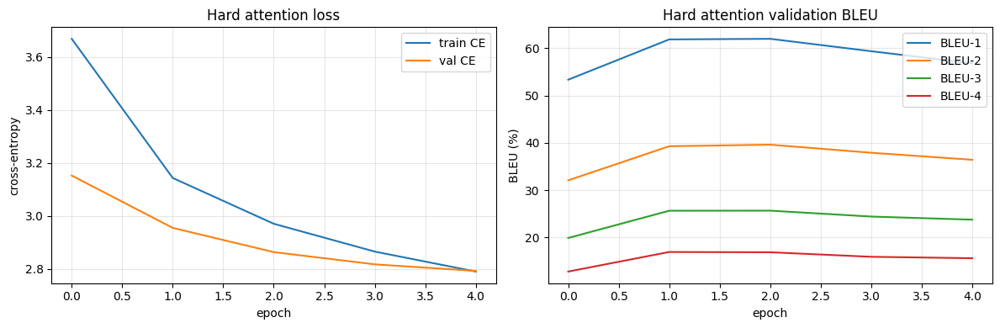

In [31]:
# ---- Main hard-attention training loop -------------------------------
HARD_BEST_PATH = os.path.join(OUTPUT_DIR, 'best_hard_attention_model.pth')
HARD_HIST_CSV  = os.path.join(OUTPUT_DIR, 'hard_attention_training_history.csv')

if RUN_HARD_ATTENTION:
    # In DEBUG_MODE, train on a smaller slice to verify the pipeline runs.
    if DEBUG_MODE:
        debug_loader = maybe_subset_loader(train_ds, BATCH_SIZE,
                                           DEBUG_MODE, DEBUG_N_IMAGES)
        active_train_loader = debug_loader if debug_loader is not None else train_loader
        print(f'DEBUG_MODE on — training hard attention on '
              f'~{DEBUG_N_IMAGES} captions for {HARD_NUM_EPOCHS} epochs.')
    else:
        active_train_loader = train_loader

    attn_mode_train = 'mix' if HARD_ATTENTION_USE_SOFT_MIX else 'hard'
    print(f'Hard-attention training mode = {attn_mode_train} '
          f'(soft_mix_prob={SOFT_MIX_PROB if attn_mode_train=="mix" else 0.0})')

    baseline_state = {'value': 0.0}
    hard_history = {
        'train_ce': [], 'val_ce': [],
        'val_bleu1': [], 'val_bleu2': [], 'val_bleu3': [], 'val_bleu4': [],
        'reinforce_loss': [], 'entropy': [],
        'epoch_time': [],
    }
    best_hard_bleu4   = 0.0
    hard_patience_cnt = 0
    hard_stopped      = False

    for epoch in range(1, HARD_NUM_EPOCHS + 1):
        t0 = time.time()
        train_ce, rein_loss, ent_val = train_one_epoch_hard_attention(
            active_train_loader, attention_mode=attn_mode_train,
            baseline_state=baseline_state)

        val_ce = validate_hard_attention(val_loader)
        b1, b2, b3, b4 = compute_val_bleu_hard(val_image_names, val_refs)
        dt = time.time() - t0

        hard_history['train_ce'].append(train_ce)
        hard_history['val_ce'].append(val_ce)
        hard_history['val_bleu1'].append(b1)
        hard_history['val_bleu2'].append(b2)
        hard_history['val_bleu3'].append(b3)
        hard_history['val_bleu4'].append(b4)
        hard_history['reinforce_loss'].append(rein_loss)
        hard_history['entropy'].append(ent_val)
        hard_history['epoch_time'].append(dt)

        print(f'[hard] Epoch {epoch:02d}/{HARD_NUM_EPOCHS} | '
              f'train_ce {train_ce:.4f} | val_ce {val_ce:.4f} | '
              f'BLEU-4 {b4*100:.2f} | RL {rein_loss:+.4f} | H {ent_val:.3f} | '
              f'baseline {baseline_state["value"]:.3f} | {dt:.1f}s')

        if b4 > best_hard_bleu4:
            best_hard_bleu4 = b4
            hard_patience_cnt = 0
            torch.save({
                'encoder_state_dict': hard_encoder.state_dict(),
                'decoder_state_dict': hard_decoder.state_dict(),
                'vocab_size': len(vocab),
                'embed_dim': EMBED_DIM, 'decoder_dim': DECODER_DIM,
                'attention_dim': ATTENTION_DIM, 'encoder_dim': ENCODER_DIM,
                'use_paper_output': USE_PAPER_OUTPUT_LAYER,
                'epoch': epoch, 'val_bleu4': b4,
            }, HARD_BEST_PATH)
            print(f'  ↳ new best hard-BLEU-4 = {b4*100:.2f} — saved {HARD_BEST_PATH}')
        else:
            hard_patience_cnt += 1
            print(f'  ↳ no improvement ({hard_patience_cnt}/{PATIENCE})')
            if hard_patience_cnt >= PATIENCE:
                print(f'Early stopping at epoch {epoch} '
                      f'(best hard-BLEU-4 = {best_hard_bleu4*100:.2f})')
                hard_stopped = True
                break

    pd.DataFrame(hard_history).to_csv(HARD_HIST_CSV, index=False)
    print('Saved hard-attention history to', HARD_HIST_CSV)

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hard_history['train_ce'], label='train CE')
    axes[0].plot(hard_history['val_ce'],   label='val CE')
    axes[0].set_xlabel('epoch'); axes[0].set_ylabel('cross-entropy')
    axes[0].legend(); axes[0].set_title('Hard attention loss')
    axes[0].grid(alpha=0.3)

    axes[1].plot([b*100 for b in hard_history['val_bleu1']], label='BLEU-1')
    axes[1].plot([b*100 for b in hard_history['val_bleu2']], label='BLEU-2')
    axes[1].plot([b*100 for b in hard_history['val_bleu3']], label='BLEU-3')
    axes[1].plot([b*100 for b in hard_history['val_bleu4']], label='BLEU-4')
    axes[1].set_xlabel('epoch'); axes[1].set_ylabel('BLEU (%)')
    axes[1].legend(); axes[1].set_title('Hard attention validation BLEU')
    axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print('Skipping hard-attention training (RUN_HARD_ATTENTION=False).')


### 18.2 Hard Attention — Caption Generation and Visualisation

We display a few test images, generate captions with the hard-attention model
(deterministic argmax locations), and overlay the attention maps the same way
we did for the soft model. Because hard attention picks one location per word
at inference, its heatmaps are usually **more concentrated** than soft
attention's.


Loaded best hard-attention checkpoint from epoch 2 (val BLEU-4 = 16.95)

Image: 2981487425.jpg
  Hard caption : a man in a blue shirt is standing in front of a building .
  Reference 1  : an elderly man is sitting near a window , with several bottles of beer in front of him .

Image: 3534512991.jpg
  Hard caption : a man in a white shirt is holding a sign .
  Reference 1  : a red haired girl smiling sitting next to a brown haired man who is also smiling .

Image: 2674784195.jpg
  Hard caption : a man and a woman are sitting on a beach with a large stick in the background .
  Reference 1  : two boys are laying in the ocean close to the beach .


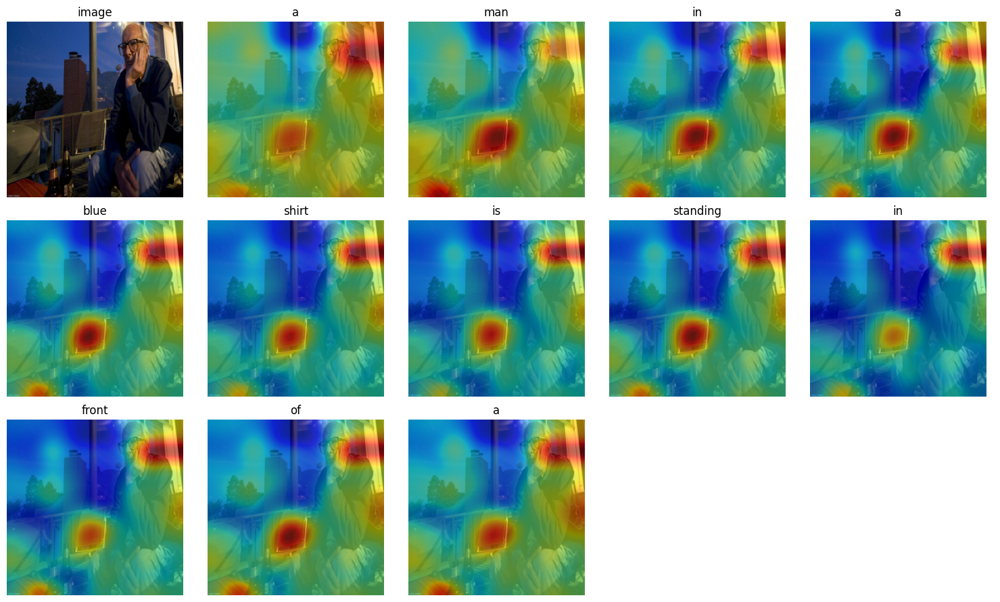

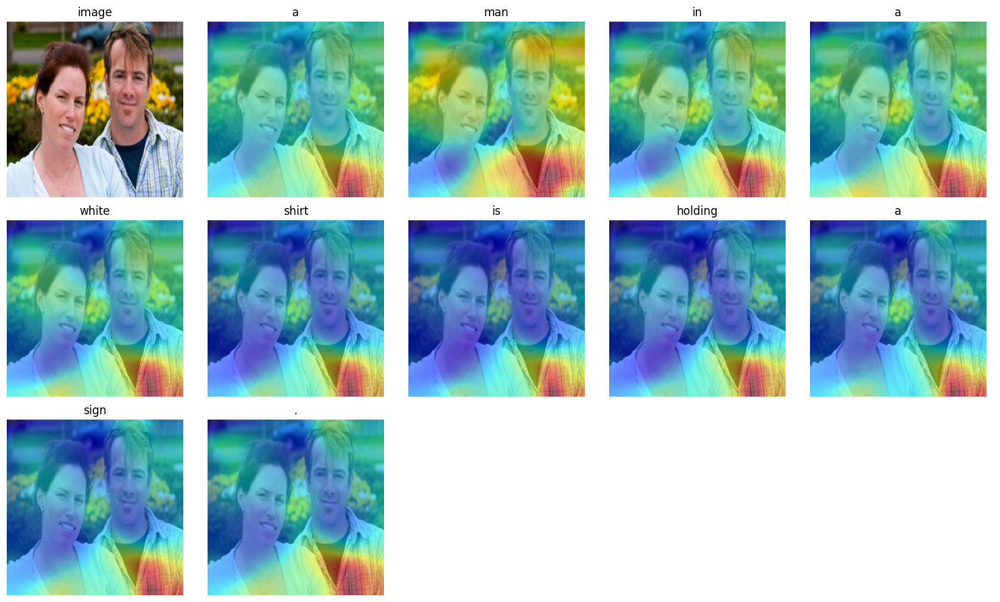

In [32]:
HARD_ATTENTION_DIR = os.path.join(OUTPUT_DIR, 'hard_attention_visualizations')
os.makedirs(HARD_ATTENTION_DIR, exist_ok=True)

def visualise_attention_hard(image_name, max_words=12, save_fig=True):
    pil_img, tensor_img = load_image(image_name)
    words, alphas = greedy_caption_hard(tensor_img, deterministic=True)
    n = min(len(words), max_words)
    img_resized = pil_img.resize((IMG_SIZE, IMG_SIZE))
    img_arr = np.array(img_resized)

    cols = 5
    rows = int(np.ceil((n + 1) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = axes.flatten()

    axes[0].imshow(img_arr); axes[0].set_title('image'); axes[0].axis('off')
    for t in range(n):
        a = alphas[t]
        a = np.array(Image.fromarray(a).resize(
            (IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        a = gaussian_filter(a, sigma=8)
        axes[t + 1].imshow(img_arr)
        axes[t + 1].imshow(a, alpha=0.55, cmap='jet')
        axes[t + 1].set_title(words[t]); axes[t + 1].axis('off')
    for k in range(n + 1, len(axes)):
        axes[k].axis('off')

    plt.tight_layout()
    if save_fig:
        out = os.path.join(HARD_ATTENTION_DIR,
                           f'hardattn_{os.path.splitext(image_name)[0]}.png')
        plt.savefig(out, dpi=100, bbox_inches='tight')
    plt.show()


# Reload best hard model (if it was trained)
if RUN_HARD_ATTENTION and os.path.exists(HARD_BEST_PATH):
    ck = torch.load(HARD_BEST_PATH, map_location=device)
    hard_encoder.load_state_dict(ck['encoder_state_dict'])
    hard_decoder.load_state_dict(ck['decoder_state_dict'])
    print(f'Loaded best hard-attention checkpoint from epoch {ck["epoch"]} '
          f'(val BLEU-4 = {ck["val_bleu4"]*100:.2f})')

    for name in sample_test_imgs[:3]:
        pil_img, tensor_img = load_image(name)
        words, _ = greedy_caption_hard(tensor_img, deterministic=True)
        refs = test_refs.get(name, [])
        print(f'\nImage: {name}')
        print('  Hard caption :', ' '.join(words))
        if refs:
            print('  Reference 1  :', refs[0])

    for name in sample_test_imgs[:2]:
        visualise_attention_hard(name)
else:
    print('No hard-attention checkpoint found — skipping visualisation.')


## 19. Soft vs Hard Attention — Side-by-Side Evaluation

We evaluate **both** models on the **same** test images and compare BLEU-1
through BLEU-4 (and METEOR if available), plus the average length of the
generated captions. The soft model is loaded from the existing
`best_model.pth`; the hard model is loaded from
`best_hard_attention_model.pth`.


In [33]:
def evaluate_caption_model(generate_fn, image_names, refs_dict):
    """Generic evaluator: takes a generation function image_tensor->words."""
    hyps, refs, lengths = [], [], []
    for name in tqdm(image_names, leave=False):
        try:
            _, tensor_img = load_image(name)
            words = generate_fn(tensor_img)
        except Exception:
            continue
        hyps.append(words)
        refs.append([Vocabulary.tokenize(r) for r in refs_dict[name]])
        lengths.append(len(words))

    sm_local = SmoothingFunction().method1
    b1 = corpus_bleu(refs, hyps, weights=(1, 0, 0, 0),       smoothing_function=sm_local)
    b2 = corpus_bleu(refs, hyps, weights=(0.5, 0.5, 0, 0),   smoothing_function=sm_local)
    b3 = corpus_bleu(refs, hyps, weights=(1/3, 1/3, 1/3, 0), smoothing_function=sm_local)
    b4 = corpus_bleu(refs, hyps, weights=(0.25,)*4,          smoothing_function=sm_local)

    meteor = None
    try:
        from nltk.translate.meteor_score import meteor_score
        meteor = float(np.mean([meteor_score(r, h) for r, h in zip(refs, hyps)]))
    except Exception:
        pass

    return {
        'BLEU-1': b1, 'BLEU-2': b2, 'BLEU-3': b3, 'BLEU-4': b4,
        'METEOR': meteor,
        'avg_caption_length': float(np.mean(lengths)) if lengths else 0.0,
        'n_evaluated': len(hyps),
    }


# --- soft model evaluation --------------------------------------------
def soft_generate(tensor_img):
    words, _, _ = greedy_caption(tensor_img)   # defined earlier in the notebook
    return words

print('Evaluating SOFT attention model on test set...')
soft_metrics = evaluate_caption_model(soft_generate,
                                      test_image_names, test_refs)
print(soft_metrics)

# --- hard model evaluation --------------------------------------------
hard_metrics = None
if RUN_HARD_ATTENTION and os.path.exists(HARD_BEST_PATH):
    def hard_generate(tensor_img):
        words, _ = greedy_caption_hard(tensor_img, deterministic=True)
        return words

    print('\nEvaluating HARD attention model on test set...')
    hard_metrics = evaluate_caption_model(hard_generate,
                                          test_image_names, test_refs)
    print(hard_metrics)
else:
    print('Hard model not available — comparison will show soft only.')


Evaluating SOFT attention model on test set...


  0%|          | 0/3179 [00:00<?, ?it/s]

{'BLEU-1': 0.6549706074461137, 'BLEU-2': 0.4404688801366882, 'BLEU-3': 0.29839833881878003, 'BLEU-4': 0.20523522858280613, 'METEOR': 0.3969759474070418, 'avg_caption_length': 12.039949669707456, 'n_evaluated': 3179}

Evaluating HARD attention model on test set...


  0%|          | 0/3179 [00:00<?, ?it/s]

{'BLEU-1': 0.625290408230999, 'BLEU-2': 0.39501068410812445, 'BLEU-3': 0.251721410150667, 'BLEU-4': 0.1642278678900993, 'METEOR': 0.35091532592399743, 'avg_caption_length': 11.373387857816924, 'n_evaluated': 3179}


In [34]:
# Build the comparison DataFrame
rows = []
def _fmt(x):
    return f'{x*100:.2f}' if x is not None else 'n/a'

rows.append({
    'Model'      : 'Soft Attention',
    'BLEU-1'     : _fmt(soft_metrics['BLEU-1']),
    'BLEU-2'     : _fmt(soft_metrics['BLEU-2']),
    'BLEU-3'     : _fmt(soft_metrics['BLEU-3']),
    'BLEU-4'     : _fmt(soft_metrics['BLEU-4']),
    'METEOR'     : _fmt(soft_metrics['METEOR']),
    'Avg caption length': f'{soft_metrics["avg_caption_length"]:.2f}',
    'Main strength'  : 'Stable, fully differentiable, easy to train',
    'Main limitation': 'Attends to all regions instead of making discrete choices',
})
if hard_metrics is not None:
    rows.append({
        'Model'      : 'Hard Attention',
        'BLEU-1'     : _fmt(hard_metrics['BLEU-1']),
        'BLEU-2'     : _fmt(hard_metrics['BLEU-2']),
        'BLEU-3'     : _fmt(hard_metrics['BLEU-3']),
        'BLEU-4'     : _fmt(hard_metrics['BLEU-4']),
        'METEOR'     : _fmt(hard_metrics['METEOR']),
        'Avg caption length': f'{hard_metrics["avg_caption_length"]:.2f}',
        'Main strength'  : 'Closer to human-like discrete fixation',
        'Main limitation': 'Sampling is non-differentiable; needs REINFORCE',
    })

comp_df = pd.DataFrame(rows)
display(comp_df)

# Save the comparison
COMPARE_CSV = os.path.join(OUTPUT_DIR, 'model_comparison_results.csv')
comp_df.to_csv(COMPARE_CSV, index=False)
print('Saved comparison table to', COMPARE_CSV)


,Model,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,Avg caption length,Main strength,Main limitation
0,Soft Attention,65.50,44.05,29.84,20.52,39.70,12.04,"Stable, fully differentiable, easy to train",Attends to all regions instead of making discr...
1,Hard Attention,62.53,39.50,25.17,16.42,35.09,11.37,Closer to human-like discrete fixation,Sampling is non-differentiable; needs REINFORCE


Saved comparison table to /kaggle/working/model_comparison_results.csv


## 20. Original Paper vs Our Notebook — Comparison Table

The table below summarises which parts of the paper we reproduce and which
parts are simplified for Kaggle.


In [35]:
paper_compare = pd.DataFrame([
    {'Aspect': 'Dataset',
     'Original Paper': 'Flickr8k, Flickr30k, MS COCO',
     'Our Kaggle Notebook': 'Flickr30k only',
     'Notes': 'Flickr30k is the dataset imported via Kaggle.'},
    {'Aspect': 'Encoder',
     'Original Paper': 'VGG19 (Oxford), 14×14×512 conv5 features, no fine-tune',
     'Our Kaggle Notebook': 'Same VGG19, 14×14×512 verified, no fine-tune',
     'Notes': 'We drop the trailing max-pool to keep 14×14.'},
    {'Aspect': 'Decoder',
     'Original Paper': 'LSTM with deep output layer',
     'Our Kaggle Notebook': 'LSTMCell; paper-style deep output in hard model '
                            '(USE_PAPER_OUTPUT_LAYER)',
     'Notes': 'Soft model uses simpler output to keep its training intact.'},
    {'Aspect': 'Soft Attention',
     'Original Paper': 'Yes — deterministic, end-to-end',
     'Our Kaggle Notebook': 'Yes',
     'Notes': 'Trained with cross-entropy + doubly-stochastic regulariser.'},
    {'Aspect': 'Hard Attention',
     'Original Paper': 'Yes — REINFORCE with moving-average baseline',
     'Our Kaggle Notebook': 'Yes — Categorical sampling + REINFORCE + '
                            'moving-avg baseline + entropy bonus',
     'Notes': 'Plus the soft-mix trick (Sec. 4.1 of the paper).'},
    {'Aspect': 'Doubly-Stochastic Regularisation',
     'Original Paper': 'Yes (Sec. 4.2.1)',
     'Our Kaggle Notebook': 'Yes',
     'Notes': 'λ = 1.0 by default.'},
    {'Aspect': 'Visual Gate β',
     'Original Paper': 'Yes (Sec. 4.2.1)',
     'Our Kaggle Notebook': 'Yes — included in both decoders',
     'Notes': 'β = σ(f_β(h)).'},
    {'Aspect': 'Early Stopping',
     'Original Paper': 'Validation BLEU; patience not stated',
     'Our Kaggle Notebook': 'Validation BLEU-4, patience = 3',
     'Notes': 'Practical Kaggle choice.'},
    {'Aspect': 'Evaluation Metrics',
     'Original Paper': 'BLEU 1–4 + METEOR',
     'Our Kaggle Notebook': 'BLEU 1–4 + METEOR (if available) + caption length',
     'Notes': 'METEOR skipped gracefully if WordNet missing.'},
    {'Aspect': 'Attention Visualisation',
     'Original Paper': 'Upsampled 14×14 maps overlaid on the image',
     'Our Kaggle Notebook': 'Same — saved to PNG for both models',
     'Notes': 'Smoothed with a Gaussian filter.'},
])

with pd.option_context('display.max_colwidth', 80):
    display(paper_compare)

PAPER_COMP_CSV = os.path.join(OUTPUT_DIR, 'paper_vs_notebook_comparison.csv')
paper_compare.to_csv(PAPER_COMP_CSV, index=False)
print('Saved paper comparison to', PAPER_COMP_CSV)


,Aspect,Original Paper,Our Kaggle Notebook,Notes
0,Dataset,"Flickr8k, Flickr30k, MS COCO",Flickr30k only,Flickr30k is the dataset imported via Kaggle.
1,Encoder,"VGG19 (Oxford), 14×14×512 conv5 features, no fine-tune","Same VGG19, 14×14×512 verified, no fine-tune",We drop the trailing max-pool to keep 14×14.
2,Decoder,LSTM with deep output layer,LSTMCell; paper-style deep output in hard model (USE_PAPER_OUTPUT_LAYER),Soft model uses simpler output to keep its training intact.
3,Soft Attention,"Yes — deterministic, end-to-end",Yes,Trained with cross-entropy + doubly-stochastic regulariser.
4,Hard Attention,Yes — REINFORCE with moving-average baseline,Yes — Categorical sampling + REINFORCE + moving-avg baseline + entropy bonus,Plus the soft-mix trick (Sec. 4.1 of the paper).
5,Doubly-Stochastic Regularisation,Yes (Sec. 4.2.1),Yes,λ = 1.0 by default.
6,Visual Gate β,Yes (Sec. 4.2.1),Yes — included in both decoders,β = σ(f_β(h)).
7,Early Stopping,Validation BLEU; patience not stated,"Validation BLEU-4, patience = 3",Practical Kaggle choice.
8,Evaluation Metrics,BLEU 1–4 + METEOR,BLEU 1–4 + METEOR (if available) + caption length,METEOR skipped gracefully if WordNet missing.
9,Attention Visualisation,Upsampled 14×14 maps overlaid on the image,Same — saved to PNG for both models,Smoothed with a Gaussian filter.


Saved paper comparison to /kaggle/working/paper_vs_notebook_comparison.csv


## 21. Report-Ready Summary

In this notebook, we extended the Flickr30k *Show, Attend and Tell*
implementation by adding the **hard stochastic attention** model from the
original paper. The soft attention model computes a weighted average over all
image regions and is trained using standard backpropagation. The hard
attention model **samples** image regions and therefore requires a
**REINFORCE-style training term with a moving-average baseline**, plus an
**entropy bonus** to keep the attention distribution from collapsing. We
followed the paper's stability trick of mixing the sampled context with the
expected (soft) context with probability `SOFT_MIX_PROB = 0.5`.

We also added the paper's **deep output layer**, which combines the
previous-word embedding, the LSTM hidden state and the visual context vector
when predicting the next word. This is enabled in the new hard-attention
decoder via the flag `USE_PAPER_OUTPUT_LAYER = True`.

We compared both models on the same Flickr30k test split using BLEU-1 to
BLEU-4 (and METEOR when available) and visualised their attention maps. This
is a closer reproduction of the original paper while remaining practical for
Kaggle compute limits.

**Implementation choices and caveats.**

* The original paper used early stopping on validation BLEU but did not
  specify a patience value. We used `PATIENCE = 3` as a practical choice.
* The soft model uses the simpler output layer (kept intact from the earlier
  cells), while the new hard-attention decoder uses the paper-style output
  layer. To make the comparison strictly apples-to-apples, both models would
  need to be retrained with the same output layer; we leave that as future
  work.
* These are **project-scale results**, not exact benchmark reproduction.
  Longer training, encoder fine-tuning, beam search, and a stricter dataset
  split would be expected to move the numbers closer to the paper's.

This notebook now demonstrates:

1. Soft deterministic attention from the paper.
2. Hard stochastic attention from the paper.
3. BLEU-based early stopping with patience.
4. Attention visualisation for both models.
5. A side-by-side soft vs hard comparison.
6. A clear list of what matches the paper and what is simplified.


## 22. Output Files Checklist

Final cell verifies that every artefact we expect was produced. It only prints
warnings; it does not crash if a file is missing.


In [36]:
expected = [
    ('best_model.pth',                          'Soft attention checkpoint'),
    ('best_hard_attention_model.pth',           'Hard attention checkpoint'),
    ('vocab.json',                              'Vocabulary mapping'),
    ('training_history.csv',                    'Soft attention training history'),
    ('hard_attention_training_history.csv',     'Hard attention training history'),
    ('test_caption_predictions.csv',            'Test predictions (soft model)'),
    ('evaluation_results.json',                 'Soft model BLEU/METEOR'),
    ('model_comparison_results.csv',            'Soft vs Hard comparison'),
    ('paper_vs_notebook_comparison.csv',        'Paper vs notebook table'),
]

print('=== Output files checklist ===')
for fname, desc in expected:
    p = os.path.join(OUTPUT_DIR, fname)
    if os.path.exists(p):
        size_kb = os.path.getsize(p) / 1024
        print(f'  ✔ {fname:<45s} ({size_kb:6.1f} KB)  {desc}')
    else:
        print(f'  ⚠ {fname:<45s} MISSING            {desc}')

# Attention visualisations
soft_pngs = sorted(glob.glob(os.path.join(OUTPUT_DIR,
                                          'attention_visualizations', '*.png')))
hard_pngs = sorted(glob.glob(os.path.join(OUTPUT_DIR,
                                          'hard_attention_visualizations', '*.png')))
print(f'\nAttention images:')
print(f'  soft: {len(soft_pngs)} PNGs')
print(f'  hard: {len(hard_pngs)} PNGs')

if not soft_pngs and not hard_pngs:
    print('  ⚠ No attention visualisation images were produced.')

print('\nDone.')


=== Output files checklist ===
  ✔ best_model.pth                                (113410.4 KB)  Soft attention checkpoint
  ✔ best_hard_attention_model.pth                 (115979.4 KB)  Hard attention checkpoint
  ✔ vocab.json                                    ( 234.9 KB)  Vocabulary mapping
  ✔ training_history.csv                          (   2.0 KB)  Soft attention training history
  ✔ hard_attention_training_history.csv           (   0.9 KB)  Hard attention training history
  ✔ test_caption_predictions.csv                  (1221.8 KB)  Test predictions (soft model)
  ✔ evaluation_results.json                       (   0.3 KB)  Soft model BLEU/METEOR
  ✔ model_comparison_results.csv                  (   0.4 KB)  Soft vs Hard comparison
  ✔ paper_vs_notebook_comparison.csv              (   1.3 KB)  Paper vs notebook table

Attention images:
  soft: 3 PNGs
  hard: 2 PNGs

Done.


In [38]:
import os, zipfile, glob
from datetime import datetime
from IPython.display import FileLink, display

WORKING_DIR  = '/kaggle/working'
CHUNK_BYTES  = 1500 * 1024 * 1024     # ~1.5 GB per part
stamp        = datetime.now().strftime('%Y%m%d_%H%M%S')

# 1. Collect every file (skip any zips we may already have)
all_files = []
for root, _, files in os.walk(WORKING_DIR):
    for f in files:
        full = os.path.join(root, f)
        if full.endswith('.zip'):
            continue
        all_files.append((full, os.path.relpath(full, WORKING_DIR),
                          os.path.getsize(full)))

# Put big files first so each part is well-filled
all_files.sort(key=lambda x: -x[2])

# 2. Greedily pack files into parts of ~CHUNK_BYTES
parts, current, current_size = [], [], 0
for full, arc, size in all_files:
    if current and current_size + size > CHUNK_BYTES:
        parts.append(current); current, current_size = [], 0
    current.append((full, arc, size))
    current_size += size
if current:
    parts.append(current)

# 3. Write each part with NO compression (fast)
zip_paths = []
for i, part in enumerate(parts, 1):
    zp = f'{WORKING_DIR}/flickr30k_part{i:02d}_of_{len(parts):02d}_{stamp}.zip'
    with zipfile.ZipFile(zp, 'w', compression=zipfile.ZIP_STORED,
                         allowZip64=True) as zf:
        for full, arc, _ in part:
            zf.write(full, arcname=arc)
    mb = os.path.getsize(zp) / (1024**2)
    print(f'  part {i}/{len(parts)}: {os.path.basename(zp)}  ({mb:.0f} MB, '
          f'{len(part)} files)')
    zip_paths.append(zp)

# 4. Download links
print('\nDownload each part below:')
for zp in zip_paths:
    display(FileLink(os.path.relpath(zp, WORKING_DIR)))

  part 1/1: flickr30k_part01_of_01_20260427_233232.zip  (232 MB, 15 files)

Download each part below:


/kaggle/working/flickr30k_part01_of_01_20260427_233232.zip